# 方法擴充:以全家實際路線重建 A 組(各自配送)

**對應進度:** 10/20 方法建構與分析擴充
**要解決的問題:** PoC 試作的 A 組假設「各品牌每輪都派車**專程**進入東北角」,正稿第四節已列為限制(可能高估共配效益)。本 notebook 用全家的**實際配送路線**檢驗這個假設,並建立一個前後一致的比較方法,重算共同配送的減碳潛力。

**本 notebook 的三個步驟:**

1. **看實際:** 全家的東北角門市在配送計畫中是怎麼被送的?(專程,還是順路?)
2. **量實際:** 每一趟實際路線,為了東北角門市多跑了多少公里(邊際里程)?
3. **重算 A/B:** 以「順路」為基準,用最佳化求解器重算各自配送與共同配送的邊際里程。

**為什麼重要:** 運輸部門 2024 年排放約 35.5 百萬公噸 CO₂e,佔全國約 13%,主要來自公路運輸(環境部氣候變遷署,2026);全臺便利商店 2025 年 8 月已有 14,236 家,平均每 1,659 人一家(經濟部統計處,2025)。門市越密,各品牌重複駛入同一地區的情形越常見,共同配送的減碳空間取決於「各品牌目前怎麼送」,所以 A 組必須貼近實際。

**資料:** 配送計畫(2024-01 ~ 2025-03)、門市主檔、門市核對清單 `poc/data/ne_stores_verified.csv`(四品牌 33 家);道路距離取自 OSRM(OpenStreetMap 路網),路線求解用 PyVRP。距離矩陣與求解結果有快取,重跑不必重新查詢。

In [1]:
import glob, json, math, os, time, urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyvrp import Model
from pyvrp.stop import MaxRuntime

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "poc" else os.getcwd()
P = lambda *a: os.path.join(ROOT, *a)
UA = {"User-Agent": "course-research/1.0"}
plt.rcParams.update({"font.family": "Microsoft JhengHei", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

NE_AREAS = "瑞芳|貢寮|雙溪|平溪"
BRANDS = ["7-Eleven", "全家", "OK", "萊爾富"]
BCOL = {"7-Eleven": "#2a78d6", "全家": "#1baf7a", "OK": "#eb6834", "萊爾富": "#4a3aa7"}
ROUTE_COL = {"LJ": "#2a78d6", "OP": "#eb6834", "BE": "#4a3aa7", "SE": "#1baf7a"}
DEDICATED = {"A": 224.4, "B": 109.0}   # PoC 試作(專程假設,每趟最多 20 店)

## 1. 全家東北角門市實際怎麼送

In [2]:
st = pd.read_csv(P("store_master", "store_master.csv"), encoding="utf-8-sig")
st["key"] = st["name"].str.replace("^全家", "", regex=True).str.replace("店$", "", regex=True)
st["area"] = st["address"].str.extract(r"^(..[市縣].{1,3}?[區鎮鄉市])")[0].str.replace("臺", "台")
dc = st[st["name"] == "瑞芳ＤＣ"].iloc[0]

dp = pd.concat([pd.read_csv(f, encoding="utf-8-sig", dtype=str) for f in sorted(glob.glob(P("delivery_plan", "monthly", "*.csv")))])
dp["TaskType_id"] = dp["TaskType_id"].str.zfill(2)
s = dp[~dp["Store_id"].str.contains("3001888888", na=False)].copy()
s["key"] = s["Store_Name"].str.replace("店$", "", regex=True)
s = s.merge(st[["key", "area", "lat", "lng"]], on="key", how="left")
s["is_ne"] = s["area"].str.contains(NE_AREAS, na=False)
s["date"] = pd.to_datetime(s["Delivery_Dt"])
s["route"] = s["Route_seq"].str[:2]
s["trip"] = s["Delivery_Dt"] + "|" + s["Car_licence"].fillna("NA") + "|" + s["route"] + "|" + s["TaskType_id"]
s["seqno"] = pd.to_numeric(s["Route_seq"].str[2:], errors="coerce")
s["act"] = pd.to_datetime(s["Ac_Arrive_dt_02"], errors="coerce")

ne_trips = set(s.loc[s["is_ne"], "trip"])
tr = s[s["trip"].isin(ne_trips)].dropna(subset=["lat"]).copy()
print("全家東北角門市(配送計畫中出現者):", sorted(s.loc[s["is_ne"], "key"].unique()))
print(f"含東北角門市的趟次:{len(ne_trips):,} 趟,分布在 {s.loc[s['is_ne'], 'date'].nunique()} 天(資料期間共 {s['date'].nunique()} 天)")

g = tr.groupby("trip").agg(任務=("TaskType_id", "first"), 路線=("route", "first"), 停靠店數=("key", "size"),
                           東北角店數=("is_ne", "sum"))
summary = g.groupby(["任務", "路線"]).agg(趟數=("停靠店數", "size"), 每趟停靠店數中位數=("停靠店數", "median"),
                                      其中東北角店數中位數=("東北角店數", "median"))
summary["同趟其他門市所在區(前 3 名)"] = [
    "、".join(tr[(tr["TaskType_id"] == t) & (tr["route"] == r) & ~tr["is_ne"]]["area"].value_counts().head(3).index)
    for t, r in summary.index]
summary

全家東北角門市(配送計畫中出現者): ['九份觀景', '平溪十分', '平溪平安', '瑞芳傑魚坑', '瑞芳前站', '瑞芳明燈', '瑞芳龍川', '金瓜石黃金']
含東北角門市的趟次:493 趟,分布在 350 天(資料期間共 456 天)


趟數  每趟停靠店數中位數  其中東北角店數中位數      同趟其他門市所在區(前 3 名)
任務 路線                                                  
02 BE   72        6.5         2.0         基隆市暖暖區、基隆市信義區
03 DD   13       23.0         4.0  新北市汐止區、基隆市安樂區、新北市金山區
04 WD    1        6.0         1.0  基隆市仁愛區、基隆市信義區、基隆市中正區
05 LJ   80       20.0         2.0  基隆市安樂區、新北市金山區、新北市萬里區
   OP   97       18.0         4.0  新北市汐止區、基隆市安樂區、基隆市信義區
12 QM    4       25.5         6.0  基隆市中正區、基隆市暖暖區、基隆市信義區
   SE  225       22.0         2.0  台北市文山區、新北市深坑區、新北市石碇區
A4 WD    1       14.0         3.0  基隆市仁愛區、基隆市中正區、基隆市信義區

**判讀:**
- 全家的東北角門市**沒有一趟是專程配送**:每一趟都和其他區的門市排在一起,東北角只佔每趟 2–4 家。
- 瑞芳的門市主要由晚班任務 05 的 **LJ**(基隆安樂、金山、萬里)與 **OP**(汐止、基隆)路線**順路**配送,深夜班 02 的 **BE**(暖暖)也會帶到;平溪 2 家店則由早班任務 12 的 **SE** 路線配送。
- 貢寮 2 家全家門市沒有出現在瑞芳物流中心的配送計畫中,推測由其他物流中心配送。
- **資料限制:** 東北角門市在 456 天中只有約 350 天出現,而且各月筆數差異很大,推測有部分配送不在這份資料裡。

### 1.1 路線地圖:東北角門市和哪些門市同趟

**看圖重點:**
- **OP、LJ:** 瑞芳門市幾乎都排在趟次的**前段**(出物流中心先送),再往汐止、基隆或金山去。
- **SE:** 225 趟中有 223 趟把平溪 2 店排在**最後兩站**:車子先到文山,再經深坑、石碇、坪林,最後經平溪**回程順路**送完再回瑞芳。
- 所以東北角門市不是「專程」,而是排在出車的起點或回程的終點附近,這就是邊際里程低的原因。

每條路線取一趟**代表性的實際趟次**(停靠店數等於該路線中位數的趟次之一),依實際到店順序畫出道路路線;圓點是該路線所有含東北角門市的趟次中停靠過的門市,點越大代表停靠次數越多,**加黑框的是東北角門市**。互動地圖可點圖例開關各條路線。

In [3]:
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"

MAP_ROUTES = [r for r, n in tr.groupby("route")["trip"].nunique().items() if n >= 4]   # 至少 4 趟的路線
RCOL = {"LJ": "#2a78d6", "OP": "#eb6834", "BE": "#4a3aa7", "SE": "#1baf7a", "DD": "#e87ba4", "QM": "#eda100"}
TASK = tr.groupby("route")["TaskType_id"].agg(lambda x: x.mode().iloc[0]).to_dict()
TASK_NAME = {"02": "深夜", "03": "白天", "05": "晚班", "12": "早班"}

def ordered(g):
    return g.sort_values(["act", "seqno"]) if g["act"].notna().all() else g.sort_values("seqno")

# 代表趟次:停靠店數 = 中位數,優先選有完整實際到店時間者,再取最早一趟
rep = {}
for r in MAP_ROUTES:
    gs = {t: g for t, g in tr[tr["route"] == r].groupby("trip")}
    med = int(np.median([len(g) for g in gs.values()]))
    cand = sorted(gs, key=lambda t: (abs(len(gs[t]) - med), not gs[t]["act"].notna().all(), t))
    rep[r] = (cand[0], ordered(gs[cand[0]]))

# 道路路線幾何(OSRM route,快取)
gcache = P("poc", "cache", "osrm_rebuild_routes.json")
geo = json.load(open(gcache, encoding="utf-8")) if os.path.exists(gcache) else {}
for r, (trip, g) in rep.items():
    if trip in geo:
        continue
    seq = [(dc["lng"], dc["lat"])] + list(zip(g["lng"], g["lat"])) + [(dc["lng"], dc["lat"])]
    url = ("https://router.project-osrm.org/route/v1/driving/" + ";".join(f"{x:.6f},{y:.6f}" for x, y in seq)
           + "?overview=full&geometries=geojson")
    geo[trip] = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=90))["routes"][0]["geometry"]["coordinates"]
json.dump(geo, open(gcache, "w", encoding="utf-8"))

visits = tr.groupby(["route", "key"]).agg(停靠次數=("trip", "size"), lat=("lat", "first"), lng=("lng", "first"),
                                         is_ne=("is_ne", "first"), area=("area", "first")).reset_index()
pd.DataFrame([{"路線": r, "任務": f"{TASK[r]} {TASK_NAME.get(TASK[r], '')}", "代表趟次": t.split("|")[0] + " " + t.split("|")[1],
               "停靠店數": len(g), "其中東北角": int(g["is_ne"].sum()),
               "東北角門市": "、".join(g.loc[g["is_ne"], "key"])}
              for r, (t, g) in rep.items()]).style.hide(axis="index")

路線,任務,代表趟次,停靠店數,其中東北角,東北角門市
BE,02 深夜,2024-08-21 V06,6,4,瑞芳傑魚坑、瑞芳明燈、瑞芳前站、瑞芳龍川
DD,03 白天,2024-02-09 V06,23,4,瑞芳明燈、瑞芳前站、瑞芳龍川、瑞芳傑魚坑
LJ,05 晚班,2024-06-09 V07,20,2,九份觀景、金瓜石黃金
OP,05 晚班,2024-06-10 V08,18,4,瑞芳傑魚坑、瑞芳明燈、瑞芳前站、瑞芳龍川
QM,12 早班,2024-12-19 V08,25,6,瑞芳龍川、瑞芳前站、瑞芳明燈、九份觀景、金瓜石黃金、瑞芳傑魚坑
SE,12 早班,2024-01-02 V10,22,2,平溪平安、平溪十分


In [4]:
# 東北角門市排在趟次的哪一段(前 1/3、中段、後 1/3)
rows = []
for r in MAP_ROUTES:
    for t, g in tr[tr["route"] == r].groupby("trip"):
        g = ordered(g); i = np.where(g["is_ne"].values)[0].mean(); n_ = len(g)
        rows.append({"路線": r, "位置": "前段" if i < n_ / 3 else ("後段" if i > 2 * n_ / 3 else "中段")})
pos_tab = pd.crosstab(pd.DataFrame(rows)["路線"], pd.DataFrame(rows)["位置"]).reindex(columns=["前段", "中段", "後段"], fill_value=0)
pos_tab["趟數"] = pos_tab.sum(axis=1)
pos_tab

位置,前段,中段,後段,趟數
路線,,,,
BE,32,16,24,72
DD,13,0,0,13
LJ,67,13,0,80
OP,97,0,0,97
QM,0,0,4,4
SE,2,0,223,225


In [5]:
ESRI = [dict(below="traces", sourcetype="raster", sourceattribution="Tiles © Esri",
             source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"])]
fig = go.Figure()
for r in MAP_ROUTES:
    trip, g = rep[r]
    c = geo[trip]
    name = f"{r}({TASK[r]} {TASK_NAME.get(TASK[r], '')})"
    fig.add_trace(go.Scattermapbox(lon=[p[0] for p in c], lat=[p[1] for p in c], mode="lines", line=dict(width=3, color=RCOL[r]),
                                   name=name, legendgroup=r, hoverinfo="name"))
    v = visits[visits["route"] == r]
    fig.add_trace(go.Scattermapbox(lon=v["lng"], lat=v["lat"], mode="markers", legendgroup=r, showlegend=False,
                                   marker=dict(size=6 + 14 * np.sqrt(v["停靠次數"] / v["停靠次數"].max()), color=RCOL[r], opacity=0.75),
                                   text=v["key"] + "(" + v["area"].fillna("") + ")<br>停靠 " + v["停靠次數"].astype(str) + " 次",
                                   hovertemplate="%{text}<extra>" + r + "</extra>"))
    ne_v = v[v["is_ne"]]
    fig.add_trace(go.Scattermapbox(lon=ne_v["lng"], lat=ne_v["lat"], mode="markers", legendgroup=r, showlegend=False,
                                   marker=dict(size=19, color="#0b0b0b"), hoverinfo="skip"))
    fig.add_trace(go.Scattermapbox(lon=ne_v["lng"], lat=ne_v["lat"], mode="markers", legendgroup=r, showlegend=False,
                                   marker=dict(size=13, color=RCOL[r]), text=ne_v["key"] + "(東北角)",
                                   hovertemplate="%{text}<extra>" + r + "</extra>"))
fig.add_trace(go.Scattermapbox(lon=[dc["lng"]], lat=[dc["lat"]], mode="markers+text", marker=dict(size=16, color="#e34948"),
                               text=["瑞芳物流中心"], textposition="top right", name="瑞芳物流中心"))
fig.update_layout(mapbox=dict(style="white-bg", layers=ESRI, center=dict(lat=25.07, lon=121.68), zoom=9.6),
                  height=640, margin=dict(t=40, b=0, l=0, r=0), title="含東北角門市的路線與同趟門市(代表趟次的道路路線)",
                  legend=dict(bgcolor="rgba(255,255,255,0.85)", x=0.01, y=0.99), font=dict(family="Microsoft JhengHei"))
fig.show()

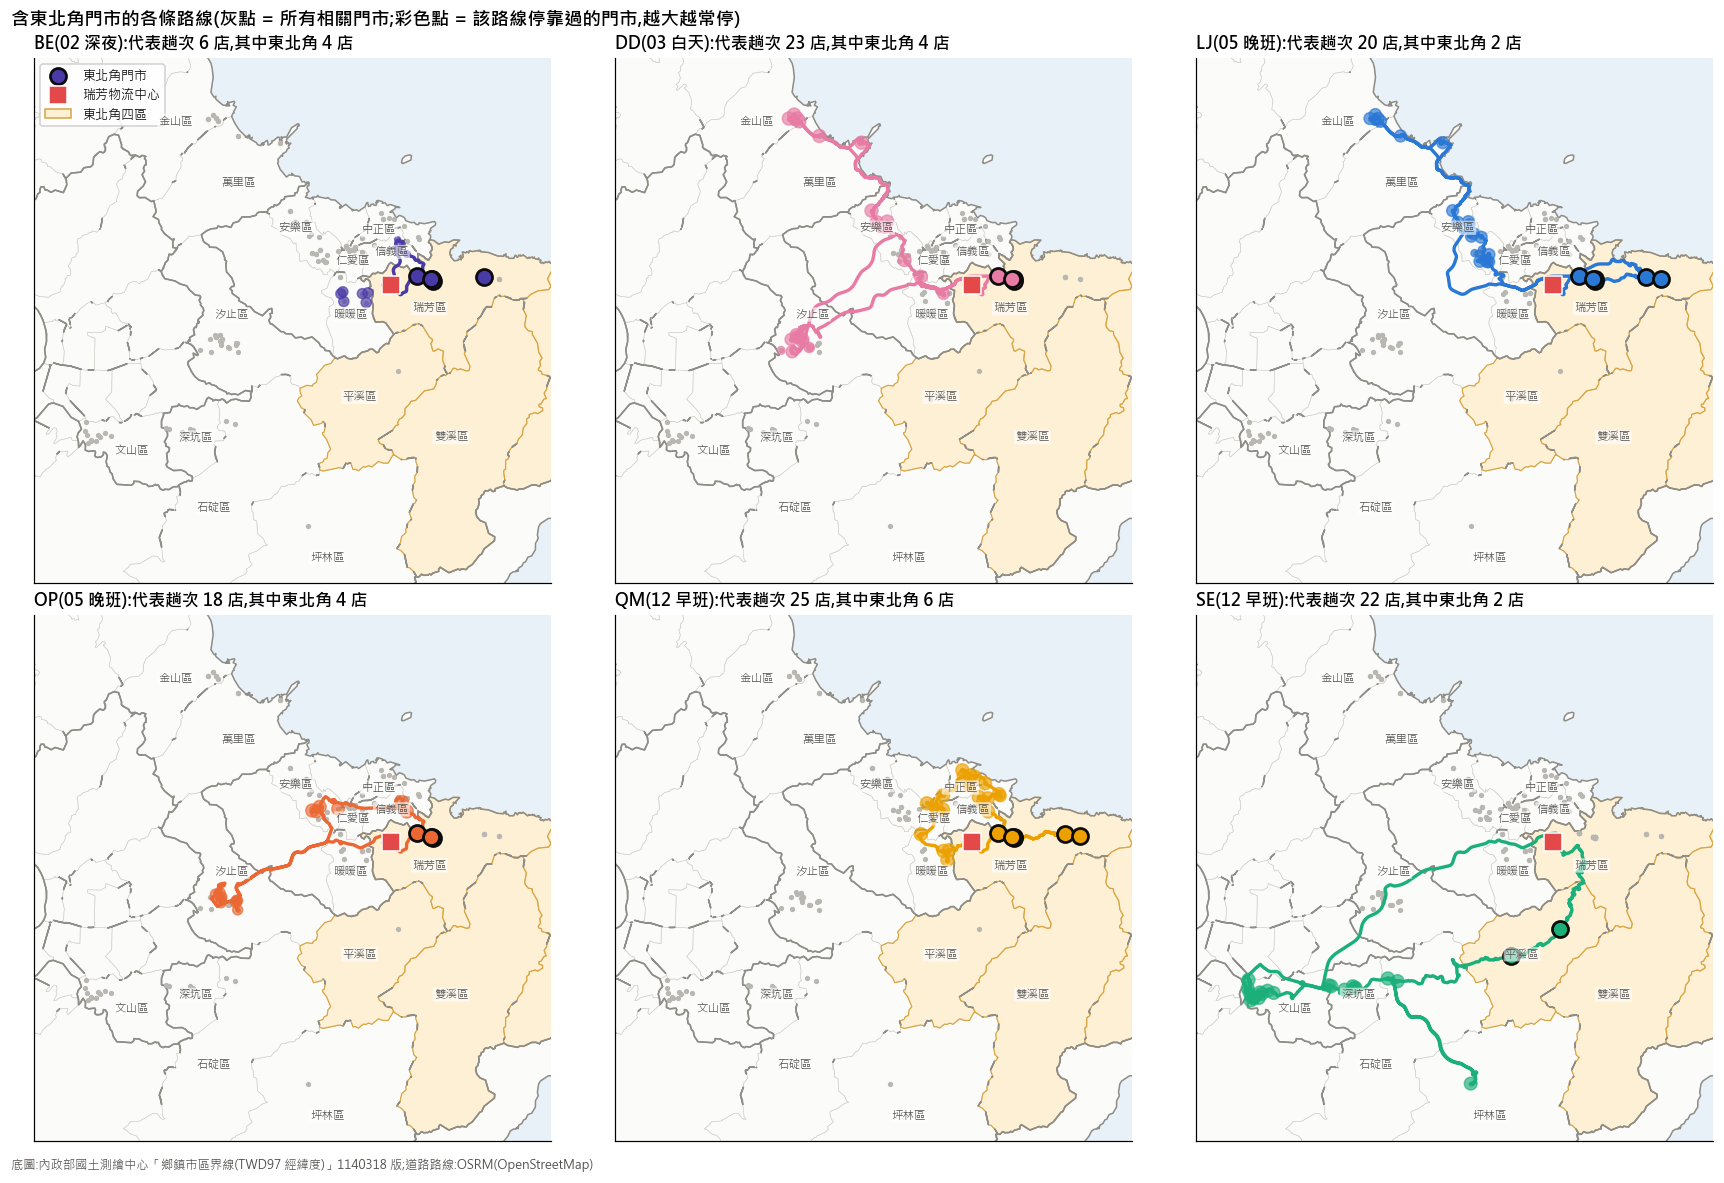

In [6]:
# 靜態小圖(每條路線一張,方便放進簡報);底圖為內政部鄉鎮市區界線(TWD97 經緯度,1140318 版)
import geopandas as gpd
from shapely.geometry import box

TOWN = gpd.read_file(P("鄉(鎮、市、區)界線1140318", "TOWN_MOI_1140318.shp"))
allv = visits.dropna(subset=["lat"])
xs = list(allv["lng"]) + [dc["lng"]]; ys = list(allv["lat"]) + [dc["lat"]]
pad = 0.04
view = box(min(xs) - pad, min(ys) - pad, max(xs) + pad, max(ys) + pad)
x0, y0, x1, y1 = view.bounds
towns = TOWN[TOWN.intersects(view)].copy()
towns["geometry"] = towns.geometry.simplify(0.0005)
counties = towns.dissolve(by="COUNTYNAME").reset_index()
ne_towns = towns[(towns["COUNTYNAME"] == "新北市") & towns["TOWNNAME"].isin(["瑞芳區", "貢寮區", "雙溪區", "平溪區"])]
served = set(allv["area"].dropna().str.replace("台", "臺"))                    # 有相關門市的「縣市+鄉鎮市區」
towns["full"] = towns["COUNTYNAME"] + towns["TOWNNAME"]
lab = towns[towns["full"].isin(served | set("新北市" + ne_towns["TOWNNAME"]))].copy()
lab["pt"] = lab.representative_point()

def basemap(ax):
    ax.set_facecolor("#e8f1f7")                                     # 海
    towns.plot(ax=ax, facecolor="#fbfbf9", edgecolor="#cfcdc7", linewidth=0.4, zorder=0)
    ne_towns.plot(ax=ax, facecolor="#fdf0d5", edgecolor="#d9a441", linewidth=0.8, zorder=0.5)
    counties.boundary.plot(ax=ax, color="#8f8d87", linewidth=1.0, zorder=0.6)
    for _, t in lab.iterrows():
        if x0 < t["pt"].x < x1 and y0 < t["pt"].y < y1:
            ax.text(t["pt"].x, t["pt"].y, t["TOWNNAME"], fontsize=7.5, color="#52514e", ha="center", va="center", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_aspect(1 / math.cos(math.radians((y0 + y1) / 2))); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

n = len(MAP_ROUTES); cols = 3; rows_ = math.ceil(n / cols)
fig, axes = plt.subplots(rows_, cols, figsize=(16, 5.4 * rows_))
axes = np.atleast_1d(axes).ravel()
for ax, r in zip(axes, MAP_ROUTES):
    trip, g = rep[r]
    c = np.array(geo[trip])
    basemap(ax)
    ax.scatter(allv["lng"], allv["lat"], s=6, color="#b9b7b1", zorder=1)
    ax.plot(c[:, 0], c[:, 1], color=RCOL[r], lw=2.2, zorder=2)
    v = visits[visits["route"] == r]
    ax.scatter(v["lng"], v["lat"], s=12 + 60 * v["停靠次數"] / v["停靠次數"].max(), color=RCOL[r], alpha=0.65, zorder=3)
    ne_v = v[v["is_ne"]]
    ax.scatter(ne_v["lng"], ne_v["lat"], s=110, facecolor=RCOL[r], edgecolor="#0b0b0b", linewidth=1.8, zorder=4, label="東北角門市")
    ax.scatter([dc["lng"]], [dc["lat"]], s=150, marker="s", color="#e34948", edgecolor="white", zorder=5, label="瑞芳物流中心")
    ax.set_title(f"{r}({TASK[r]} {TASK_NAME.get(TASK[r], '')}):代表趟次 {len(g)} 店,其中東北角 {int(g['is_ne'].sum())} 店",
                 loc="left", fontweight="bold", fontsize=11)
for ax in axes[n:]:
    ax.axis("off")

# 圖例放在第一張
from matplotlib.patches import Patch
h, l = axes[0].get_legend_handles_labels()
h += [Patch(facecolor="#fdf0d5", edgecolor="#d9a441", label="東北角四區")]
axes[0].legend(handles=h, loc="upper left", fontsize=8.5, frameon=True, framealpha=0.9)

fig.suptitle("含東北角門市的各條路線(灰點 = 所有相關門市;彩色點 = 該路線停靠過的門市,越大越常停)", x=0.01, ha="left", fontweight="bold")
fig.text(0.01, 0.005, "底圖:內政部國土測繪中心「鄉鎮市區界線(TWD97 經緯度)」1140318 版;道路路線:OSRM(OpenStreetMap)", fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.015, 1, 1)); plt.show()

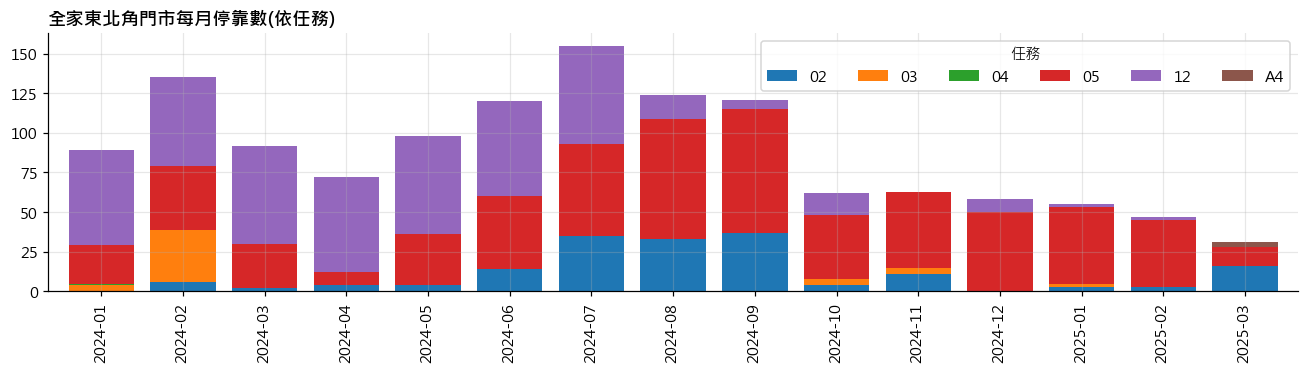

In [7]:
# 各月東北角門市停靠數(依任務)
ne = s[s["is_ne"]]
m = ne.groupby([ne["date"].dt.to_period("M").astype(str), "TaskType_id"]).size().unstack(fill_value=0)
ax = m.plot.bar(stacked=True, figsize=(12, 3.5), width=0.8)
ax.set_title("全家東北角門市每月停靠數(依任務)", loc="left", fontweight="bold"); ax.set_xlabel(""); ax.legend(title="任務", ncols=6)
plt.tight_layout(); plt.show()

## 2. 道路距離矩陣

點位包含:瑞芳物流中心、含東北角門市的趟次中所有全家門市(作為「幹線」),以及四品牌 33 家東北角門市。點數超過 OSRM 公開服務單次 100 點的上限,因此分批查詢後組合。

In [8]:
ver = pd.read_csv(P("poc", "data", "ne_stores_verified.csv"), encoding="utf-8-sig")
ver = ver[ver["include"] == 1].reset_index(drop=True)
ver["key"] = ver["name"].str.replace("^全家", "", regex=True).str.replace("店$", "", regex=True)

trip_keys = sorted(tr["key"].unique())
xy = st.drop_duplicates("key").set_index("key")
pts = [("DC", dc["lng"], dc["lat"])] + [(f"F:{k}", xy.at[k, "lng"], xy.at[k, "lat"]) for k in trip_keys]
for _, r in ver.iterrows():
    if not (r["brand"] == "全家" and r["key"] in trip_keys):
        pts.append((f"N:{r['brand']}:{r['name']}", r["lon"], r["lat"]))
names = [p[0] for p in pts]
pos = {n: i for i, n in enumerate(names)}
ver["node"] = [pos[f"F:{r['key']}"] if (r["brand"] == "全家" and r["key"] in trip_keys) else pos[f"N:{r['brand']}:{r['name']}"]
               for _, r in ver.iterrows()]

cache = P("poc", "cache", "osrm_rebuild_matrix.json")
if os.path.exists(cache) and json.load(open(cache, encoding="utf-8"))["names"] == names:
    D = json.load(open(cache, encoding="utf-8"))["D"]
else:
    n, B = len(pts), 45
    D = [[None] * n for _ in range(n)]
    blocks = [list(range(i, min(i + B, n))) for i in range(0, n, B)]
    for a in blocks:
        for b in blocks:
            ids = a + [j for j in b if j not in a]
            coords = ";".join(f"{pts[i][1]:.6f},{pts[i][2]:.6f}" for i in ids)
            src = ";".join(str(k) for k in range(len(a)))
            dst = ";".join(str(ids.index(j)) for j in b)
            url = f"https://router.project-osrm.org/table/v1/driving/{coords}?sources={src}&destinations={dst}&annotations=distance"
            r = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=180))
            assert r["code"] == "Ok", r.get("code")
            for ii, i in enumerate(a):
                for jj, j in enumerate(b):
                    D[i][j] = r["distances"][ii][jj]
    json.dump({"names": names, "D": D}, open(cache, "w", encoding="utf-8"), ensure_ascii=False)
print(f"點數 {len(pts)}(物流中心 1、全家幹線與東北角門市 {len(trip_keys)}、他牌與全家貢寮門市 {len(pts) - 1 - len(trip_keys)})")

def length(seq):
    nodes = [0] + list(seq) + [0]
    return sum(D[a][b] for a, b in zip(nodes[:-1], nodes[1:])) / 1000

點數 122(物流中心 1、全家幹線與東北角門市 96、他牌與全家貢寮門市 25)


## 3. 實際路線的邊際里程

對每一趟含東北角門市的實際路線:

**邊際里程 = 照實際順序跑完全部門市的道路里程 − 拿掉東北角門市後(其餘順序不變)的道路里程**

也就是全家為了服務東北角門市,實際多跑的距離。停靠順序依實際到店時間排序;缺實際時間的趟次改用路線站序。

趟數  整趟里程中位數  邊際里程中位數  每店邊際里程中位數
任務 路線                                  
02 BE   72     18.8      6.5        3.6
03 DD   13    104.8     13.3        3.3
04 WD    1     25.2      4.8        4.8
05 LJ   80     97.6     24.9       12.4
   OP   97     62.0      3.9        1.0
12 QM    4     56.2     20.4        3.4
   SE  225    120.0      7.6        3.8
A4 WD    1     34.2      5.3        1.8

實際路線:每停靠一家東北角門市,平均多跑 3.8 km
PoC 專程假設:全家每家東北角門市分攤 8.8 km(約實際的 2.3 倍)


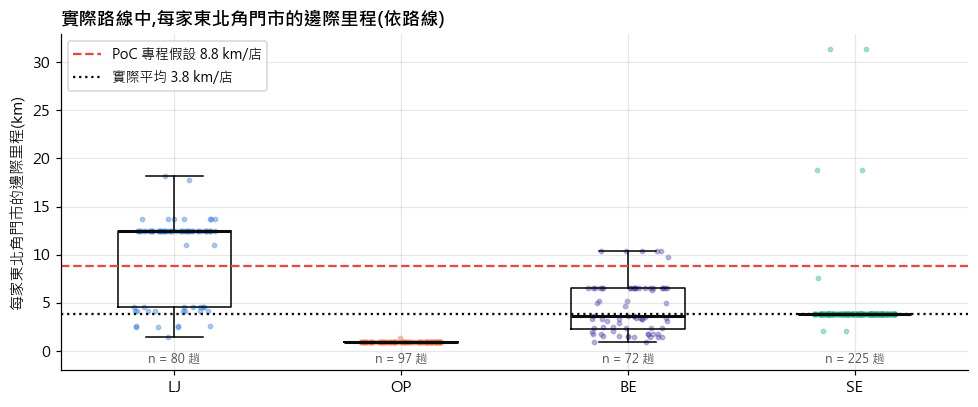

In [9]:
rows = []
for trip, g in tr.groupby("trip"):
    g = g.sort_values(["act", "seqno"]) if g["act"].notna().all() else g.sort_values("seqno")
    seq = [pos[f"F:{k}"] for k in g["key"]]
    seq_wo = [pos[f"F:{k}"] for k, ne in zip(g["key"], g["is_ne"]) if not ne]
    full, wo = length(seq), length(seq_wo)
    rows.append({"trip": trip, "任務": trip.split("|")[3], "路線": trip.split("|")[2], "停靠店數": len(seq),
                 "東北角店數": int(g["is_ne"].sum()), "整趟 km": full, "拿掉東北角後 km": wo, "邊際 km": full - wo})
M = pd.DataFrame(rows)
M["每家東北角門市邊際 km"] = M["邊際 km"] / M["東北角店數"]
tab = M.groupby(["任務", "路線"]).agg(趟數=("trip", "size"), 整趟里程中位數=("整趟 km", "median"),
                                    邊際里程中位數=("邊際 km", "median"), 每店邊際里程中位數=("每家東北角門市邊際 km", "median"))
display(tab.round(1))
per_store_actual = M["邊際 km"].sum() / M["東北角店數"].sum()
per_store_dedicated = 88.3 / 10   # PoC:全家 10 家東北角門市專程配送 88.3 km
print(f"實際路線:每停靠一家東北角門市,平均多跑 {per_store_actual:.1f} km")
print(f"PoC 專程假設:全家每家東北角門市分攤 {per_store_dedicated:.1f} km(約實際的 {per_store_dedicated / per_store_actual:.1f} 倍)")

fig, ax = plt.subplots(figsize=(9, 3.8))
main = [r for r in ["LJ", "OP", "BE", "SE"] if r in M["路線"].unique()]
rng = np.random.default_rng(0)
for i, r in enumerate(main, start=1):
    v = M.loc[M["路線"] == r, "每家東北角門市邊際 km"]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=8, alpha=0.35, color=ROUTE_COL[r])
    ax.text(i, -1.2, f"n = {len(v)} 趟", ha="center", fontsize=8, color="#52514e")
ax.boxplot([M.loc[M["路線"] == r, "每家東北角門市邊際 km"] for r in main], tick_labels=main, showfliers=False,
           widths=0.5, medianprops=dict(color="#0b0b0b", lw=2))
ax.set_ylim(-2, None)
ax.axhline(per_store_dedicated, color="#e34948", ls="--", lw=1.5, label=f"PoC 專程假設 {per_store_dedicated:.1f} km/店")
ax.axhline(per_store_actual, color="#0b0b0b", ls=":", lw=1.5, label=f"實際平均 {per_store_actual:.1f} km/店")
ax.set_ylabel("每家東北角門市的邊際里程(km)"); ax.legend(fontsize=9)
ax.set_title("實際路線中,每家東北角門市的邊際里程(依路線)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 4. 方法依據

本分析的比較框架沿用合作配送文獻的標準作法:

- **綜效 = 各自配送的成本加總 − 共同配送的成本**(Cruijssen 等,2007)。本分析以「服務東北角門市的邊際里程」作為成本。
- B 組把四品牌的門市合併成一個路線問題求解,屬於合作路線規劃中的**集中式合作規劃**(Gansterer & Hartl,2018)。
- 各品牌分得多少節省,可再用 **Shapley value** 分配(Krajewska 等,2008;Guajardo & Rönnqvist,2016),PoC 試作已示範。
- 路線以 PyVRP 求解(Wouda 等,2024)。

**比較基準與口徑:** 文獻常見的合作效益約 25–30%(Cruijssen 等 2007 綜效約 30%;Ballot & Fontane 2010 零售供應網路 CO₂ 至少減 25%),多以**整個配送網路**計算;日本函館跨品牌實證(2022)為兩品牌、7 家偏遠門市的區內段實測,里程減 22%。本分析同時報告兩種口徑:**邊際里程減幅**(只看服務東北角多跑的那段)與**路網總里程減幅**(含各品牌原本的幹線),後者才能和文獻數字並列比較。

## 5. 版本一:重新最佳化邊際里程法(上限情境)

實際資料顯示各品牌(至少全家)是**順路**配送東北角門市,所以 A/B 比較也要在「順路」的前提下進行。做法:

1. **幹線:** 從全家實際路線中,每條主要路線(LJ、OP、BE、SE)取「拿掉東北角門市後里程為中位數」的一趟,代表一條典型幹線。
2. **基準:** 用 PyVRP 求「只送幹線門市」的最短路線,里程記為 $L_0$。
3. **A 組(各自配送):** 每個品牌 $b$ 把自家東北角門市加入幹線後重新求解,里程 $L_b$;品牌 $b$ 的邊際里程為 $L_b - L_0$。**A 組 = 四品牌邊際里程加總。**
4. **B 組(共同配送):** 四品牌 33 家店一起加入同一組幹線後求解,里程 $L_{all}$。**B 組 = $L_{all} - L_0$。**
5. 兩組的差,就是「共用繞進東北角的那段路」省下的距離。

**假設:** 其他品牌也有與全家相似、經過汐止/基隆或深坑的幹線(他牌實際路線無法取得);每趟停靠上限 $Q$ 取 20、25、30 店做敏感度;每個情境以 3 個隨機種子求解取最佳值,降低求解器誤差。

**不同班次分開算:** 晚班 05(LJ + OP)、早班 12(SE)屬於不同時段與溫層,不能同車,所以分開計算;另列「四條合併」作對照。

In [10]:
trunks = {}
for r in ["LJ", "OP", "BE", "SE"]:
    cand = []
    for trip, g in tr[tr["route"] == r].groupby("trip"):
        g = g.sort_values(["act", "seqno"]) if g["act"].notna().all() else g.sort_values("seqno")
        seq = [pos[f"F:{k}"] for k, ne in zip(g["key"], g["is_ne"]) if not ne]
        cand.append((length(seq), trip, seq))
    cand.sort(key=lambda x: x[0])
    L, trip, seq = cand[len(cand) // 2]
    trunks[r] = seq
    print(f"幹線 {r}:{trip},拿掉東北角後 {len(seq)} 家店、{L:.1f} km")

NE = {b: ver.loc[ver["brand"] == b, "node"].tolist() for b in BRANDS}
ALL = ver["node"].tolist()

def vrp(ids, Q, secs=2, seeds=(1, 2, 3)):
    best = None
    for sd in seeds:
        m = Model(); l0 = m.add_location(0, 0); m.add_depot(l0)
        m.add_vehicle_type(num_available=len(ids), capacity=Q)
        locs = [l0] + [m.add_location(0, 0) for _ in ids]
        for L in locs[1:]:
            m.add_client(L, delivery=1)
        g = [0] + list(ids)
        for a, la in zip(g, locs):
            for b, lb in zip(g, locs):
                m.add_edge(la, lb, distance=int(D[a][b]))
        sol = m.solve(stop=MaxRuntime(secs), seed=sd, display=False).best
        v = (sol.distance() / 1000, sol.num_routes())
        if best is None or v[0] < best[0]:
            best = v
    return best

幹線 LJ:2024-08-15|V14|LJ|05,拿掉東北角後 18 家店、72.7 km
幹線 OP:2024-07-21|V10|OP|05,拿掉東北角後 15 家店、58.1 km


幹線 BE:2024-07-03|V18|BE|02,拿掉東北角後 3 家店、14.0 km


幹線 SE:2024-04-12|V13|SE|12,拿掉東北角後 20 家店、112.4 km


## 6. 版本一結果:各情境的邊際里程

In [11]:
SCEN = [("晚班 05(LJ+OP)", ["LJ", "OP"]), ("早班 12(SE)", ["SE"]), ("四條合併", ["LJ", "OP", "BE", "SE"])]
QS = [20, 25, 30]
rcache = P("poc", "cache", "rebuild_results.json")
if os.path.exists(rcache):
    res = json.load(open(rcache, encoding="utf-8"))
else:
    res, t0 = [], time.time()
    for label, rts in SCEN:
        trunk = sorted(set(sum((trunks[r] for r in rts), [])))
        for Q in QS:
            base = vrp(trunk, Q)
            A = {b: vrp(trunk + NE[b], Q)[0] - base[0] for b in BRANDS}
            Bv = vrp(trunk + ALL, Q)
            res.append({"幹線": label, "Q": Q, "基準 km": base[0], "基準趟數": base[1], **{f"A_{b}": A[b] for b in BRANDS},
                        "A 組邊際 km": sum(A.values()), "B 組邊際 km": Bv[0] - base[0], "B 趟數": Bv[1]})
            print(f"{label} Q={Q} 完成({time.time() - t0:.0f} 秒)")
    json.dump(res, open(rcache, "w", encoding="utf-8"), ensure_ascii=False)
R = pd.DataFrame(res)
R["減少 km"] = R["A 組邊際 km"] - R["B 組邊際 km"]
R["邊際里程減幅"] = R["減少 km"] / R["A 組邊際 km"]
# 路網層級:四品牌各自跑一條幹線 + 東北角邊際
R["路網總里程減幅"] = R["減少 km"] / (4 * R["基準 km"] + R["A 組邊際 km"])
R.style.format({c: "{:.1f}" for c in R.columns if "km" in c or c.startswith("A_")} |
               {"邊際里程減幅": "{:.0%}", "路網總里程減幅": "{:.0%}"}).hide(axis="index")

幹線,Q,基準 km,基準趟數,A_7-Eleven,A_全家,A_OK,A_萊爾富,A 組邊際 km,B 組邊際 km,B 趟數,減少 km,邊際里程減幅,路網總里程減幅
晚班 05(LJ+OP),20,123.0,2,64.5,76.3,6.6,17.5,164.9,102.5,4,62.3,38%,9%
晚班 05(LJ+OP),25,119.0,2,56.9,66.3,9.0,19.3,151.5,81.3,3,70.2,46%,11%
晚班 05(LJ+OP),30,119.0,2,57.0,66.4,7.0,17.5,147.9,81.3,3,66.5,45%,11%
早班 12(SE),20,102.4,1,69.8,88.3,22.0,24.4,204.5,106.1,3,98.4,48%,16%
早班 12(SE),25,102.4,1,64.9,68.8,10.2,19.3,163.2,87.6,3,75.6,46%,13%
早班 12(SE),30,102.4,1,55.8,49.6,10.2,19.3,134.9,77.5,2,57.4,43%,11%
四條合併,20,226.6,3,64.5,76.1,6.4,17.5,164.6,102.5,5,62.0,38%,6%
四條合併,25,220.4,3,57.2,66.1,7.7,17.5,148.5,81.3,4,67.3,45%,7%
四條合併,30,184.2,2,64.8,79.4,6.9,18.4,169.5,87.4,3,82.1,48%,9%


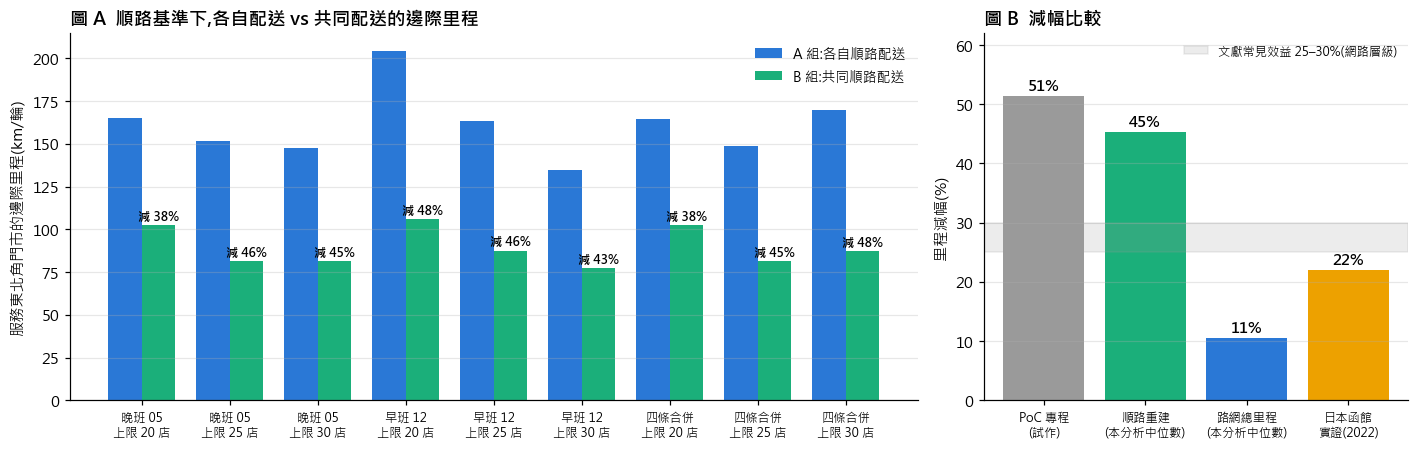

邊際里程減幅範圍:38% ~ 48%;路網總里程減幅範圍:6% ~ 16%
A 組邊際里程範圍:135 ~ 205 km(PoC 專程 224.4 km)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
lab = [f"{a.split('(')[0]}\n上限 {q} 店" for a, q in zip(R["幹線"], R["Q"])]
x = np.arange(len(R)); w = 0.38
axes[0].bar(x - w / 2, R["A 組邊際 km"], w, color="#2a78d6", label="A 組:各自順路配送")
axes[0].bar(x + w / 2, R["B 組邊際 km"], w, color="#1baf7a", label="B 組:共同順路配送")
for i, p in enumerate(R["邊際里程減幅"]):
    axes[0].text(i + w / 2, R["B 組邊際 km"].iloc[i] + 3, f"減 {p:.0%}", ha="center", fontsize=8, fontweight="bold")
axes[0].set_xticks(x, lab, fontsize=8); axes[0].set_ylabel("服務東北角門市的邊際里程(km/輪)")
axes[0].legend(fontsize=9, frameon=False); axes[0].grid(axis="x", visible=False)
axes[0].set_title("圖 A  順路基準下,各自配送 vs 共同配送的邊際里程", loc="left", fontweight="bold")

cmp = pd.DataFrame({"PoC 專程\n(試作)": [1 - DEDICATED["B"] / DEDICATED["A"]],
                    "順路重建\n(本分析中位數)": [R["邊際里程減幅"].median()],
                    "路網總里程\n(本分析中位數)": [R["路網總里程減幅"].median()],
                    "日本函館\n實證(2022)": [0.22]}).T[0]
bars = axes[1].bar(cmp.index, cmp.values * 100, color=["#9a9a9a", "#1baf7a", "#2a78d6", "#eda100"])
for b_, v in zip(bars, cmp.values):
    axes[1].text(b_.get_x() + b_.get_width() / 2, v * 100 + 1, f"{v:.0%}", ha="center", fontweight="bold")
axes[1].axhspan(25, 30, color="#9a9a9a", alpha=0.18, label="文獻常見效益 25–30%(網路層級)")
axes[1].legend(fontsize=8, loc="upper right", frameon=False)
axes[1].set_ylim(0, 62)
axes[1].set_ylabel("里程減幅(%)"); axes[1].grid(axis="x", visible=False); axes[1].tick_params(axis="x", labelsize=8)
axes[1].set_title("圖 B  減幅比較", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"邊際里程減幅範圍:{R['邊際里程減幅'].min():.0%} ~ {R['邊際里程減幅'].max():.0%};"
      f"路網總里程減幅範圍:{R['路網總里程減幅'].min():.0%} ~ {R['路網總里程減幅'].max():.0%}")
print(f"A 組邊際里程範圍:{R['A 組邊際 km'].min():.0f} ~ {R['A 組邊際 km'].max():.0f} km(PoC 專程 {DEDICATED['A']} km)")

### 6.1 版本一路線地圖:重新最佳化後各自配送與共同配送怎麼跑

上表的每個數字都來自求解器解出的路線。這裡挑一個代表情境(**晚班 05:LJ + OP 幹線,每趟上限 25 店**,減幅接近 9 個情境的中位數)重新求解並畫出路線:

- **基準:** 只送幹線門市(汐止、基隆、金山等)的最短路線。
- **A 組(4 張):** 每個品牌各自把自家東北角門市加進自己的幹線;標題寫的「多跑」就是該品牌的邊際里程。
- **B 組:** 四品牌 33 家東北角門市一起加進**同一組**幹線。

A 組 4 張的「多跑」加總,減去 B 組的「多跑」,就是共同配送省下的里程。

**版本一的問題(看圖可見):** 求解器要求每個品牌的 10 家東北角門市在**同一個班次**全部送完,且可以重排整條幹線,結果全家與 7-Eleven 各自派車繞「瑞芳 → 貢寮 → 雙溪 → 平溪」一大圈,等於又回到 PoC 的專程配送。這和第 1 節看到的全家實際做法不同(平溪由早班 SE 回程順路、貢寮不由瑞芳配送、每趟只帶 2–4 家)。因此版本一只能當**上限情境**,主要結果改用第 7 節的校準版。

In [13]:
MAP_SCEN, MAP_RTS, MAP_Q = "晚班 05(LJ+OP)", ["LJ", "OP"], 25

def vrp_routes(ids, Q, secs=2, seeds=(1, 2, 3)):
    # 與 vrp() 相同,但多回傳每趟的停靠順序(節點編號)
    best = None
    for sd in seeds:
        m = Model(); l0 = m.add_location(0, 0); m.add_depot(l0)
        m.add_vehicle_type(num_available=len(ids), capacity=Q)
        locs = [l0] + [m.add_location(0, 0) for _ in ids]
        for L in locs[1:]:
            m.add_client(L, delivery=1)
        g = [0] + list(ids)
        for a, la in zip(g, locs):
            for b, lb in zip(g, locs):
                m.add_edge(la, lb, distance=int(D[a][b]))
        sol = m.solve(stop=MaxRuntime(secs), seed=sd, display=False).best
        km = sol.distance() / 1000
        if best is None or km < best[0]:
            best = (km, [[ids[a.idx] for a in r.schedule() if a.is_client()] for r in sol.routes()])
    return best

mcache = P("poc", "cache", "rebuild_map_routes.json")
mkey = f"{MAP_SCEN}|Q{MAP_Q}"
store = json.load(open(mcache, encoding="utf-8")) if os.path.exists(mcache) else {}
if mkey not in store:
    trunk = sorted(set(sum((trunks[r] for r in MAP_RTS), [])))
    sol = {"基準": vrp_routes(trunk, MAP_Q)}
    for b in BRANDS:
        sol[f"A_{b}"] = vrp_routes(trunk + NE[b], MAP_Q)
    sol["B"] = vrp_routes(trunk + ALL, MAP_Q)
    store[mkey] = sol
    json.dump(store, open(mcache, "w", encoding="utf-8"), ensure_ascii=False)
sol = store[mkey]
base_km = sol["基準"][0]
add = {k: v[0] - base_km for k, v in sol.items() if k != "基準"}
A_sum = sum(add[f"A_{b}"] for b in BRANDS)
print(f"情境:{MAP_SCEN},每趟上限 {MAP_Q} 店;基準 {base_km:.1f} km")
print("A 組各品牌多跑:" + "、".join(f"{b} {add[f'A_{b}']:.1f} km" for b in BRANDS) + f";合計 {A_sum:.1f} km")
print(f"B 組多跑:{add['B']:.1f} km → 省下 {A_sum - add['B']:.1f} km(邊際里程減 {1 - add['B'] / A_sum:.0%})")
print("(重新求解的數字可能與上表差 1–2 km,因求解器以時間為停止條件)")

情境:晚班 05(LJ+OP),每趟上限 25 店;基準 119.0 km
A 組各品牌多跑:7-Eleven 56.9 km、全家 66.3 km、OK 9.0 km、萊爾富 19.3 km;合計 151.5 km
B 組多跑:81.3 km → 省下 70.2 km(邊際里程減 46%)
(重新求解的數字可能與上表差 1–2 km,因求解器以時間為停止條件)


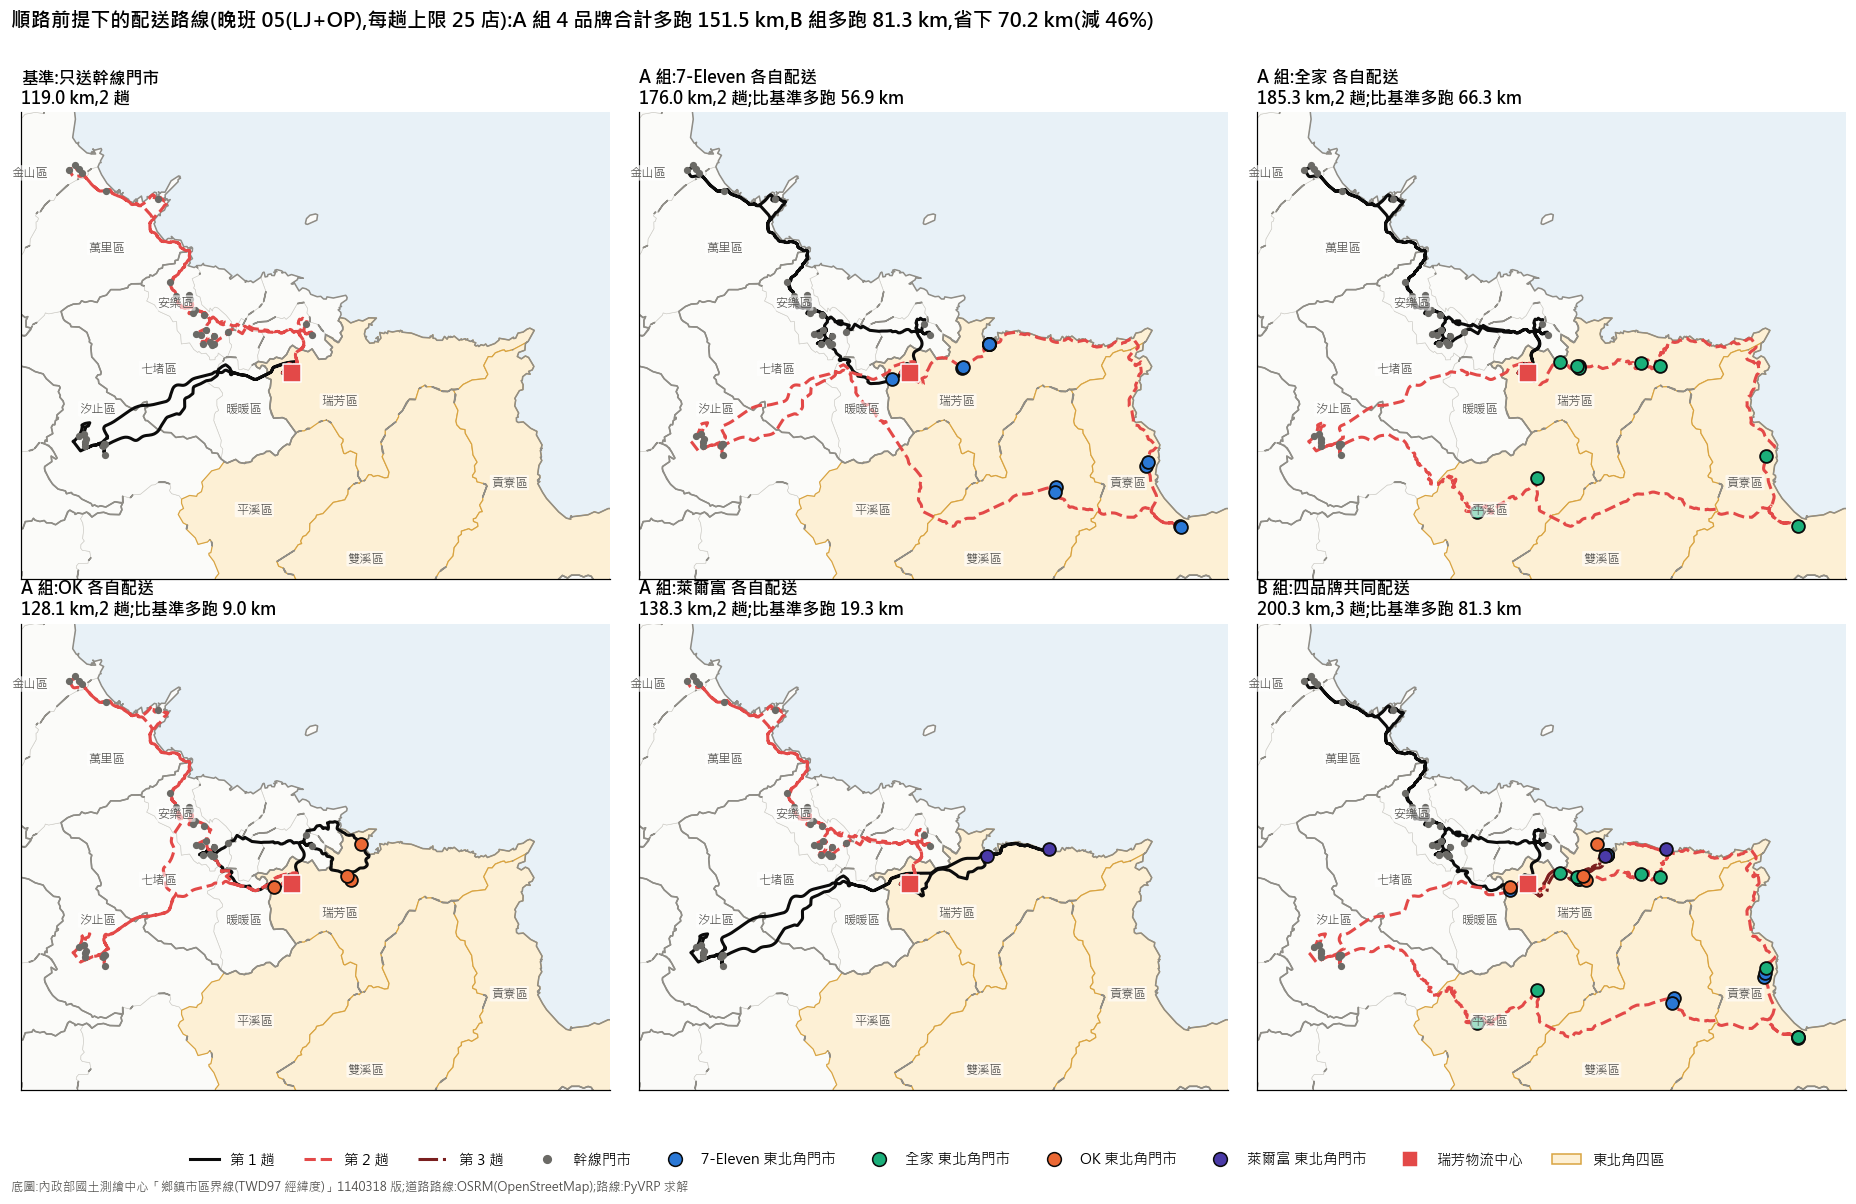

In [14]:
# 每趟路線的道路幾何(OSRM route,與 1.1 節共用快取)
def road(seq_nodes):
    seq = [(pts[0][1], pts[0][2])] + [(pts[i][1], pts[i][2]) for i in seq_nodes] + [(pts[0][1], pts[0][2])]
    key = ";".join(f"{x:.6f},{y:.6f}" for x, y in seq)
    if key not in geo:
        url = f"https://router.project-osrm.org/route/v1/driving/{key}?overview=full&geometries=geojson"
        geo[key] = json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=90))["routes"][0]["geometry"]["coordinates"]
    return np.array(geo[key])

panels = [("基準:只送幹線門市", "基準", [])] + [(f"A 組:{b} 各自配送", f"A_{b}", [b]) for b in BRANDS] + \
         [("B 組:四品牌共同配送", "B", BRANDS)]
lines = {k: [road(r) for r in sol[k][1]] for _, k, _ in panels}
json.dump(geo, open(gcache, "w", encoding="utf-8"))

trunk_nodes = sorted(set(sum((trunks[r] for r in MAP_RTS), [])))
allx = [pts[i][1] for i in trunk_nodes + ALL] + [pts[0][1]]
ally = [pts[i][2] for i in trunk_nodes + ALL] + [pts[0][2]]
X0, X1, Y0, Y1 = min(allx) - 0.03, max(allx) + 0.03, min(ally) - 0.03, max(ally) + 0.03
vbox = box(X0, Y0, X1, Y1)
twn = TOWN[TOWN.intersects(vbox)].copy(); twn["geometry"] = twn.geometry.simplify(0.0005)
cty = twn.dissolve(by="COUNTYNAME").reset_index()
ne4 = twn[(twn["COUNTYNAME"] == "新北市") & twn["TOWNNAME"].isin(["瑞芳區", "貢寮區", "雙溪區", "平溪區"])]
lab2 = twn[twn["TOWNNAME"].isin(["瑞芳區", "貢寮區", "雙溪區", "平溪區", "汐止區", "金山區", "萬里區", "暖暖區", "安樂區", "七堵區"])].copy()
lab2["pt"] = lab2.representative_point()
VCOL = ["#0b0b0b", "#e34948", "#7a1f1f", "#9a9a9a", "#e87ba4"]
VLS = ["-", "--", "-.", ":", "-"]

fig, axes = plt.subplots(2, 3, figsize=(17, 11))
for ax, (title, k, brs) in zip(axes.ravel(), panels):
    ax.set_facecolor("#e8f1f7")
    twn.plot(ax=ax, facecolor="#fbfbf9", edgecolor="#cfcdc7", linewidth=0.4, zorder=0)
    ne4.plot(ax=ax, facecolor="#fdf0d5", edgecolor="#d9a441", linewidth=0.8, zorder=0.5)
    cty.boundary.plot(ax=ax, color="#8f8d87", linewidth=1.0, zorder=0.6)
    for _, t in lab2.iterrows():
        if X0 < t["pt"].x < X1 and Y0 < t["pt"].y < Y1:
            ax.text(t["pt"].x, t["pt"].y, t["TOWNNAME"], fontsize=8, color="#52514e", ha="center", va="center", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))
    for j, c in enumerate(lines[k]):
        ax.plot(c[:, 0], c[:, 1], color=VCOL[j % len(VCOL)], ls=VLS[j % len(VLS)], lw=2, zorder=2, label=f"第 {j + 1} 趟")
    ax.scatter([pts[i][1] for i in trunk_nodes], [pts[i][2] for i in trunk_nodes], s=14, color="#6b6a66", zorder=3, label="幹線門市")
    for b in brs:
        nd = NE[b]
        ax.scatter([pts[i][1] for i in nd], [pts[i][2] for i in nd], s=70, color=BCOL[b], edgecolor="#0b0b0b", linewidth=1.2,
                   zorder=4, label=f"{b} 東北角門市")
    ax.scatter([pts[0][1]], [pts[0][2]], s=150, marker="s", color="#e34948", edgecolor="white", zorder=5, label="瑞芳物流中心")
    km = sol[k][0]
    sub = f"{km:.1f} km,{len(sol[k][1])} 趟" + ("" if k == "基準" else f";比基準多跑 {km - base_km:.1f} km")
    ax.set_title(f"{title}\n{sub}", loc="left", fontweight="bold", fontsize=11)
    ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1); ax.set_aspect(1 / math.cos(math.radians((Y0 + Y1) / 2)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
nveh = max(len(sol[k][1]) for _, k, _ in panels)
hd = [Line2D([0], [0], color=VCOL[j], ls=VLS[j], lw=2, label=f"第 {j + 1} 趟") for j in range(nveh)]
hd += [Line2D([0], [0], marker="o", ls="", color="#6b6a66", markersize=5, label="幹線門市")]
hd += [Line2D([0], [0], marker="o", ls="", markerfacecolor=BCOL[b], markeredgecolor="#0b0b0b", markersize=9, label=f"{b} 東北角門市")
       for b in BRANDS]
hd += [Line2D([0], [0], marker="s", ls="", markerfacecolor="#e34948", markeredgecolor="white", markersize=10, label="瑞芳物流中心"),
       Patch(facecolor="#fdf0d5", edgecolor="#d9a441", label="東北角四區")]
fig.legend(handles=hd, loc="lower center", ncols=len(hd), fontsize=9.5, frameon=False, bbox_to_anchor=(0.5, 0.012))
fig.suptitle(f"順路前提下的配送路線({MAP_SCEN},每趟上限 {MAP_Q} 店):A 組 4 品牌合計多跑 {A_sum:.1f} km,"
             f"B 組多跑 {add['B']:.1f} km,省下 {A_sum - add['B']:.1f} km(減 {1 - add['B'] / A_sum:.0%})",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.005, "底圖:內政部國土測繪中心「鄉鎮市區界線(TWD97 經緯度)」1140318 版;道路路線:OSRM(OpenStreetMap);路線:PyVRP 求解",
         fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.045, 1, 0.97)); plt.show()

## 7. 校準版:照全家實際做法重建(主要結果)

**四個原則:**

1. **分區照實際班次:** 瑞芳區門市(含九份、金瓜石)放進晚班 05 的 LJ、OP 幹線;平溪區門市放進早班 12 的 SE 幹線(全家實際由 SE 回程順路配送);貢寮、雙溪不在任何全家幹線上,列為**偏遠門市**。
2. **幹線順序固定:** 只把門市插入實際趟次的最佳位置,不重排幹線(與第 3 節量測實際邊際里程的方法一致);插入採 regret 插入法(先處理「插錯位置代價最大」的門市)。每趟超過上限的門市才另派車。
3. **先驗證:** 用同一套方法算全家,每店邊際里程應接近實際的 3.8 km,才能拿來推論他牌。
4. **偏遠門市分兩種情境:** **R1** 由瑞芳專程配送(A 組各品牌各派一車、B 組共派一車);**R2** 由其他物流中心配送,不納入比較(全家貢寮 2 店的實際情況)。

他牌沒有實際路線,假設他們的門市也照同一分區、插入同樣的幹線。

In [15]:
ZONE = {"瑞芳區": "05", "平溪區": "12", "貢寮區": "偏遠", "雙溪區": "偏遠"}
ver["zone"] = ver["district"].map(ZONE)
LAYER = {"05": ["LJ", "OP"], "12": ["SE"]}
display(pd.crosstab(ver["brand"], ver["zone"].map({"05": "瑞芳(晚班 05)", "12": "平溪(早班 12)", "偏遠": "貢寮、雙溪(偏遠)"}),
                    margins=True, margins_name="合計").reindex(BRANDS + ["合計"]))

def zone_nodes(brs, z):
    return ver.loc[ver["brand"].isin(brs) & (ver["zone"] == z), "node"].tolist()

def insert_fixed(routes, stores, Q):
    # regret 插入:幹線既有順序不變,只決定新門市插在哪兩站之間;回傳增加里程(km)、新路線、塞不下的門市
    routes = {k: list(v) for k, v in routes.items()}
    left, added = list(stores), 0.0
    while left:
        best = None
        for sid in left:
            opts = []
            for rk, seq in routes.items():
                if len(seq) >= Q:
                    continue
                nodes = [0] + seq + [0]
                c, pp = min((D[nodes[q]][sid] + D[sid][nodes[q + 1]] - D[nodes[q]][nodes[q + 1]], q) for q in range(len(nodes) - 1))
                opts.append((c, rk, pp))
            if not opts:
                continue
            opts.sort()
            regret = opts[1][0] - opts[0][0] if len(opts) > 1 else 1e12
            cand = (regret, -opts[0][0], sid, opts[0][1], opts[0][2])
            if best is None or cand[:2] > best[:2]:
                best = cand
        if best is None:
            break
        _, negc, sid, rk, pp = best
        routes[rk].insert(pp, sid); added -= negc; left.remove(sid)
    return added / 1000, routes, left

def serve_layer(layer, nodes, Q):
    km, rts, left = insert_fixed({r: trunks[r] for r in LAYER[layer]}, nodes, Q)
    ext = vrp_routes(left, Q) if left else (0.0, [])
    return {"km": km + ext[0], "routes": rts, "extra": ext[1], "overflow": len(left)}

def dedicated(nodes, Q):
    km, rts = vrp_routes(nodes, Q) if nodes else (0.0, [])
    return {"km": km, "routes": rts}

ccache = P("poc", "cache", "rebuild_calibrated.json")
CAL = json.load(open(ccache, encoding="utf-8")) if os.path.exists(ccache) else {}
for Q in [22, 25, 30]:
    if str(Q) in CAL:
        continue
    out = {}
    for who, brs in [(b, [b]) for b in BRANDS] + [("B", BRANDS)]:
        out[who] = {"05": serve_layer("05", zone_nodes(brs, "05"), Q), "12": serve_layer("12", zone_nodes(brs, "12"), Q),
                    "remote": dedicated(zone_nodes(brs, "偏遠"), Q)}
    CAL[str(Q)] = out
json.dump(CAL, open(ccache, "w", encoding="utf-8"), ensure_ascii=False)
TRUNK_BASE = sum(length(trunks[r]) for r in ["LJ", "OP", "SE"])   # 一個品牌的三條幹線(固定順序)
print("幹線(固定順序):" + "、".join(f"{r} {length(trunks[r]):.1f} km / {len(trunks[r])} 店" for r in ["LJ", "OP", "SE"]))

zone,平溪(早班 12),瑞芳(晚班 05),貢寮、雙溪(偏遠),合計
brand,,,,
7-Eleven,1,10,6,17
全家,2,6,2,10
OK,0,4,0,4
萊爾富,0,2,0,2
合計,3,22,8,33


幹線(固定順序):LJ 72.7 km / 18 店、OP 58.1 km / 15 店、SE 112.4 km / 20 店


### 7.1 驗證:模型能否重現全家的實際邊際里程

In [16]:
q = CAL["25"]["全家"]
n05, n12 = len(zone_nodes(["全家"], "05")), len(zone_nodes(["全家"], "12"))
model_per = (q["05"]["km"] + q["12"]["km"]) / (n05 + n12)
val = pd.DataFrame([
    {"項目": "瑞芳區 6 店插入晚班 05 幹線", "模型邊際里程 km": q["05"]["km"], "每店 km": q["05"]["km"] / n05},
    {"項目": "平溪區 2 店插入早班 12 幹線", "模型邊際里程 km": q["12"]["km"], "每店 km": q["12"]["km"] / n12},
    {"項目": "合計(瑞芳物流中心實際服務的 8 店)", "模型邊際里程 km": q["05"]["km"] + q["12"]["km"], "每店 km": model_per},
])
display(val.style.format({"模型邊際里程 km": "{:.1f}", "每店 km": "{:.1f}"}).hide(axis="index"))
print(f"實際路線(第 3 節):每停靠一家東北角門市平均 {per_store_actual:.1f} km;模型 {model_per:.1f} km;"
      f"版本一(重新最佳化)全家每店 {R.loc[(R['幹線'].str.startswith('晚班')) & (R['Q'] == 25), 'A_全家'].iloc[0] / 10:.1f} km")

項目,模型邊際里程 km,每店 km
瑞芳區 6 店插入晚班 05 幹線,19.8,3.3
平溪區 2 店插入早班 12 幹線,7.6,3.8
合計(瑞芳物流中心實際服務的 8 店),27.4,3.4


實際路線(第 3 節):每停靠一家東北角門市平均 3.8 km;模型 3.4 km;版本一(重新最佳化)全家每店 6.6 km


### 7.2 結果:校準版的 A/B 比較

In [17]:
rows = []
for Q in [22, 25, 30]:
    c = CAL[str(Q)]
    A = {z: sum(c[b][z]["km"] for b in BRANDS) for z in ["05", "12", "remote"]}
    B = {z: c["B"][z]["km"] for z in ["05", "12", "remote"]}
    for sc, zs in [("R1 偏遠由瑞芳專程", ["05", "12", "remote"]), ("R2 偏遠不納入", ["05", "12"])]:
        a, b = sum(A[z] for z in zs), sum(B[z] for z in zs)
        rows.append({"情境": sc, "每趟上限": Q, "A 瑞芳": A["05"], "A 平溪": A["12"], "A 偏遠": A["remote"] if "remote" in zs else 0,
                     "A 組邊際 km": a, "B 瑞芳": B["05"], "B 平溪": B["12"], "B 偏遠": B["remote"] if "remote" in zs else 0,
                     "B 組邊際 km": b, "減少 km": a - b, "邊際里程減幅": (a - b) / a,
                     "路網總里程減幅": (a - b) / (4 * TRUNK_BASE + a),
                     "B 超載加派(瑞芳/平溪)": f"{c['B']['05']['overflow']}/{c['B']['12']['overflow']} 店"})
CR = pd.DataFrame(rows)
CR.style.format({c: "{:.1f}" for c in CR.columns if c.startswith(("A ", "B ", "減少")) and "超載" not in c} |
                {"邊際里程減幅": "{:.0%}", "路網總里程減幅": "{:.0%}"}).hide(axis="index")

情境,每趟上限,A 瑞芳,A 平溪,A 偏遠,A 組邊際 km,B 瑞芳,B 平溪,B 偏遠,B 組邊際 km,減少 km,邊際里程減幅,路網總里程減幅,B 超載加派(瑞芳/平溪)
R1 偏遠由瑞芳專程,22,63.8,18.3,136.1,218.2,46.8,23.5,66.9,137.2,81.0,37%,7%,11/1 店
R2 偏遠不納入,22,63.8,18.3,0.0,82.2,46.8,23.5,0.0,70.3,11.8,14%,1%,11/1 店
R1 偏遠由瑞芳專程,25,52.7,18.3,136.1,207.1,46.9,18.3,66.9,132.1,75.0,36%,6%,5/0 店
R2 偏遠不納入,25,52.7,18.3,0.0,71.0,46.9,18.3,0.0,65.3,5.8,8%,1%,5/0 店
R1 偏遠由瑞芳專程,30,52.7,18.3,136.1,207.1,32.2,18.3,66.9,117.4,89.7,43%,8%,0/0 店
R2 偏遠不納入,30,52.7,18.3,0.0,71.0,32.2,18.3,0.0,50.5,20.5,29%,2%,0/0 店


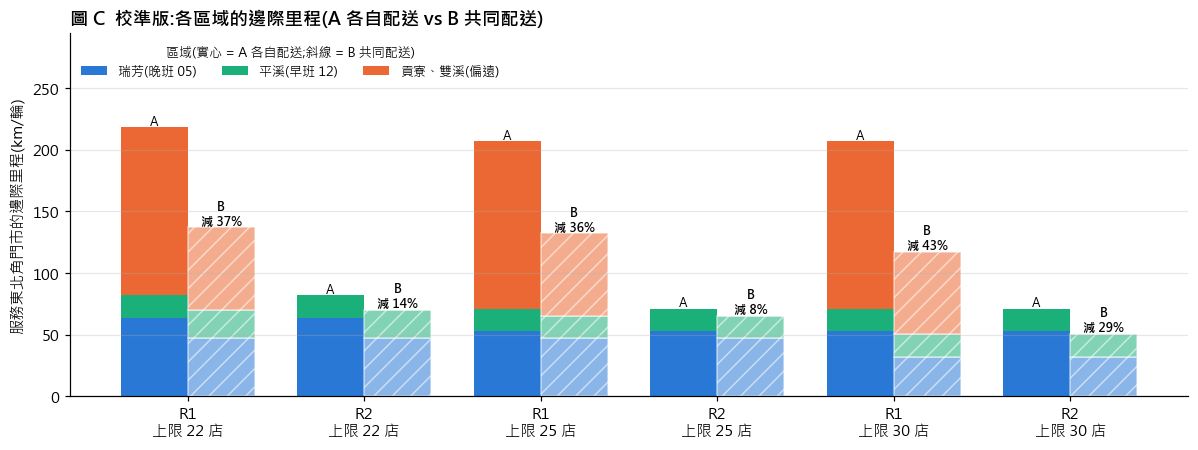

R1 偏遠由瑞芳專程:邊際里程減幅 36% ~ 43%;路網總里程減幅 6% ~ 8%;A 組邊際 207 ~ 218 km
R2 偏遠不納入:邊際里程減幅 8% ~ 29%;路網總里程減幅 1% ~ 2%;A 組邊際 71 ~ 82 km


In [18]:
fig, ax = plt.subplots(figsize=(11, 4.2))
lab_ = [f"{r['情境'][:2]}\n上限 {r['每趟上限']} 店" for _, r in CR.iterrows()]
x = np.arange(len(CR)); w = 0.38
for i, (zA, zB, col, nm) in enumerate([("A 瑞芳", "B 瑞芳", "#2a78d6", "瑞芳(晚班 05)"), ("A 平溪", "B 平溪", "#1baf7a", "平溪(早班 12)"),
                                        ("A 偏遠", "B 偏遠", "#eb6834", "貢寮、雙溪(偏遠)")]):
    bA = CR[["A 瑞芳", "A 平溪", "A 偏遠"]].iloc[:, :i].sum(axis=1)
    bB = CR[["B 瑞芳", "B 平溪", "B 偏遠"]].iloc[:, :i].sum(axis=1)
    ax.bar(x - w / 2, CR[zA], w, bottom=bA, color=col, label=nm)
    ax.bar(x + w / 2, CR[zB], w, bottom=bB, color=col, alpha=0.55, hatch="//", edgecolor="white")
for i, r in CR.iterrows():
    ax.text(i - w / 2, r["A 組邊際 km"] + 2, "A", ha="center", fontsize=8)
    ax.text(i + w / 2, r["B 組邊際 km"] + 2, f"B\n減 {r['邊際里程減幅']:.0%}", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(x, lab_); ax.set_ylabel("服務東北角門市的邊際里程(km/輪)"); ax.grid(axis="x", visible=False)
ax.legend(title="區域(實心 = A 各自配送;斜線 = B 共同配送)", fontsize=8.5, title_fontsize=8.5, frameon=False, ncols=3, loc="upper left")
ax.set_ylim(0, CR["A 組邊際 km"].max() * 1.35)
ax.set_title("圖 C  校準版:各區域的邊際里程(A 各自配送 vs B 共同配送)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
for sc in CR["情境"].unique():
    d = CR[CR["情境"] == sc]
    print(f"{sc}:邊際里程減幅 {d['邊際里程減幅'].min():.0%} ~ {d['邊際里程減幅'].max():.0%};"
          f"路網總里程減幅 {d['路網總里程減幅'].min():.0%} ~ {d['路網總里程減幅'].max():.0%};"
          f"A 組邊際 {d['A 組邊際 km'].min():.0f} ~ {d['A 組邊際 km'].max():.0f} km")

### 7.3 校準版路線地圖(每趟上限 25 店)

幹線維持全家實際的停靠順序;黑線 LJ、紅虛線 OP 為晚班 05,金色線 SE 為早班 12;灰點線是幹線塞不下時加派的車;褐色點線是 R1 情境下偏遠門市的專程車。

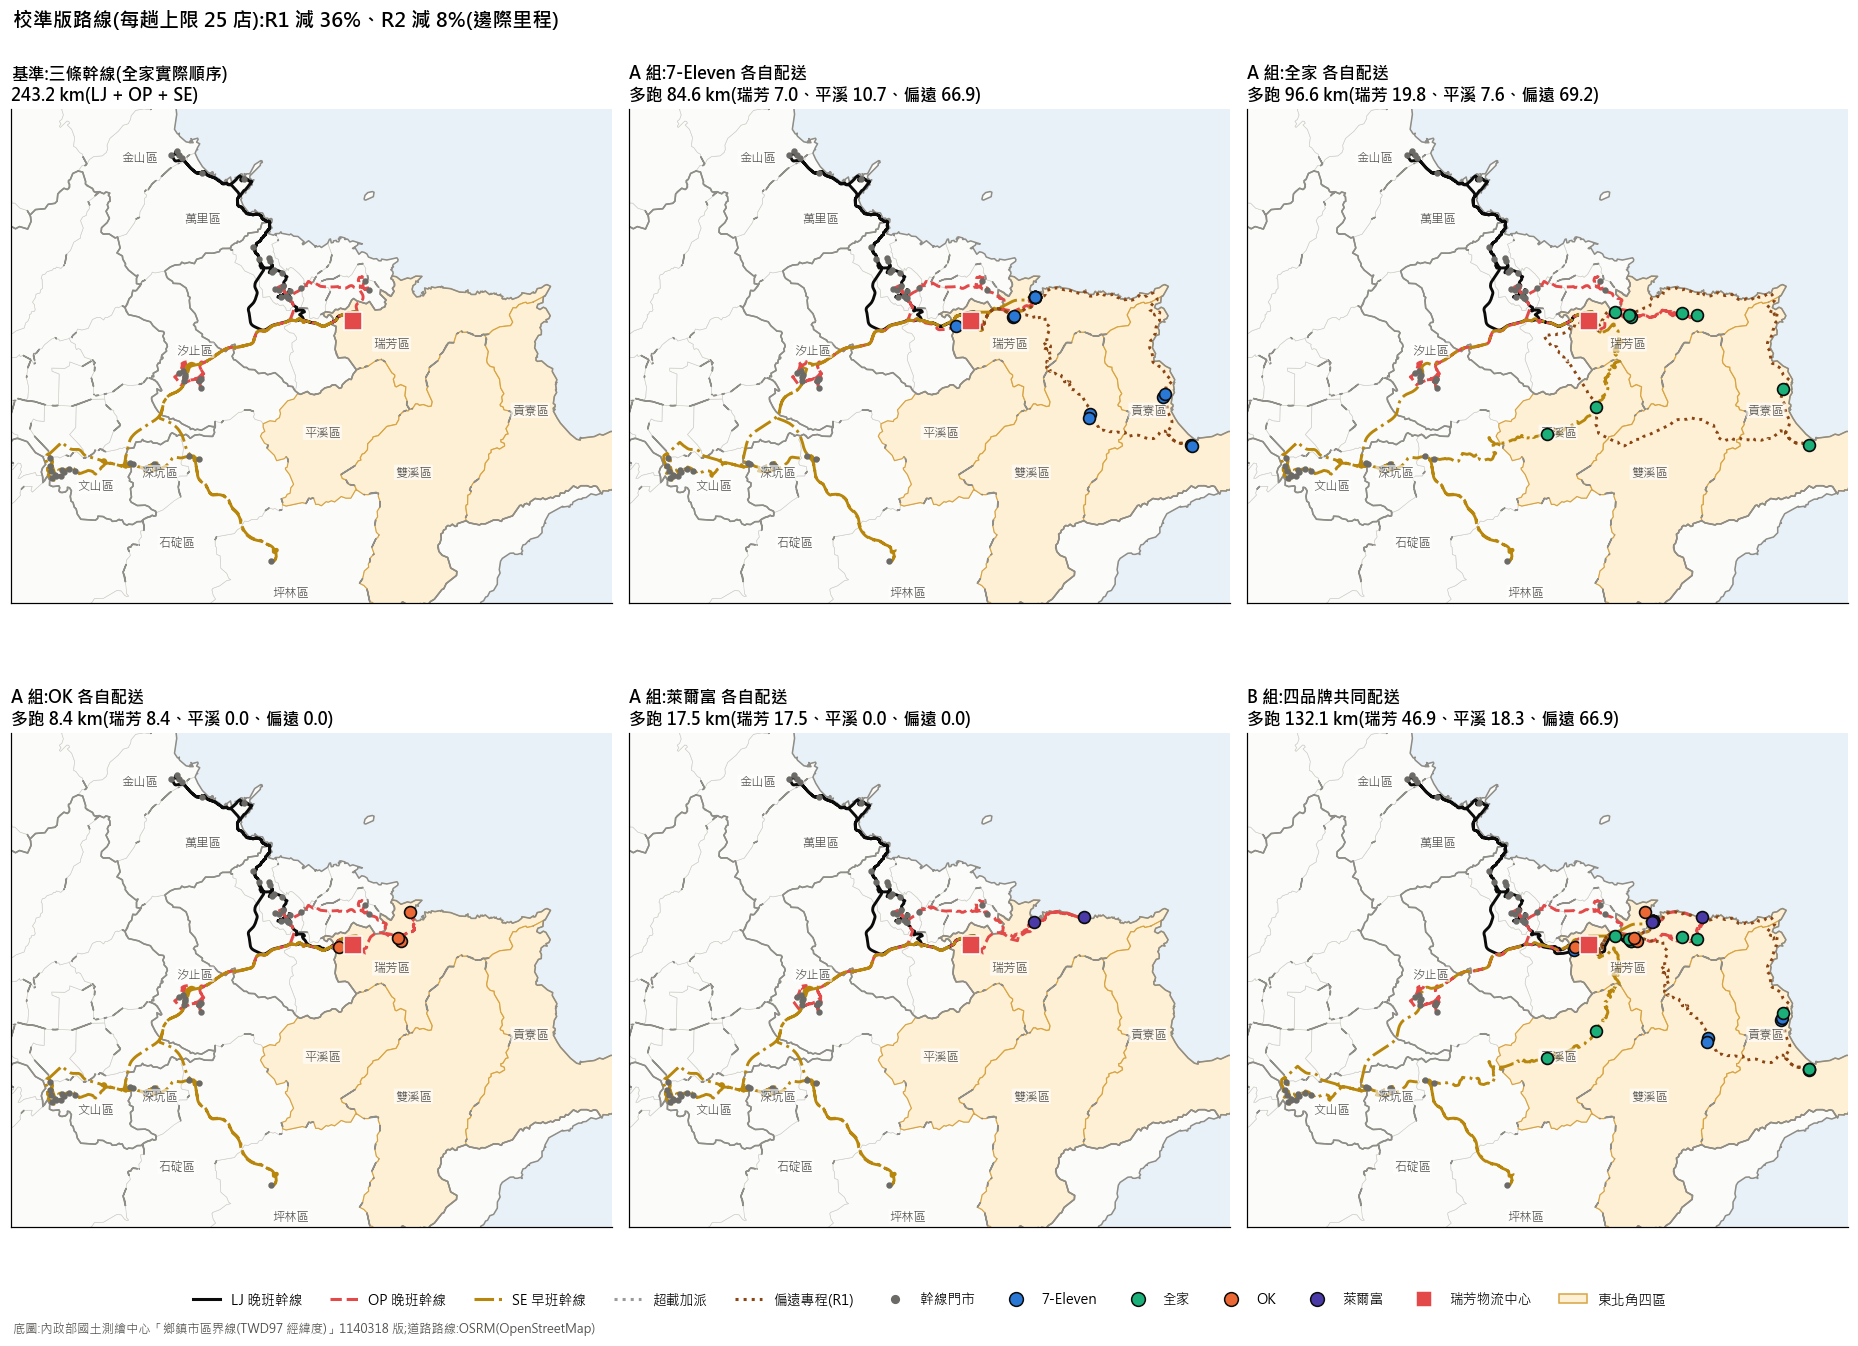

In [19]:
c25 = CAL["25"]
RSTY = {"LJ": dict(color="#0b0b0b", ls="-"), "OP": dict(color="#e34948", ls="--"), "SE": dict(color="#b8860b", ls="-."),
        "加派": dict(color="#9a9a9a", ls=":"), "偏遠專程": dict(color="#8b4513", ls=":")}

def panel_routes(entry):
    out = []
    for layer in ["05", "12"]:
        for rk, seq in entry[layer]["routes"].items():
            out.append((rk, seq))
        out += [("加派", seq) for seq in entry[layer]["extra"]]
    out += [("偏遠專程", seq) for seq in entry.get("remote", {}).get("routes", [])]
    return out

base_entry = {"05": {"routes": {r: trunks[r] for r in LAYER["05"]}, "extra": []},
              "12": {"routes": {r: trunks[r] for r in LAYER["12"]}, "extra": []}}
cpanels = [("基準:三條幹線(全家實際順序)", base_entry, [])] + [(f"A 組:{b} 各自配送", c25[b], [b]) for b in BRANDS] + \
          [("B 組:四品牌共同配送", c25["B"], BRANDS)]
clines = [[(k, road(seq)) for k, seq in panel_routes(e) if seq] for _, e, _ in cpanels]
json.dump(geo, open(gcache, "w", encoding="utf-8"))

nodes_all = sorted(set(sum((trunks[r] for r in ["LJ", "OP", "SE"]), [])) | set(ALL))
CX0, CX1 = min(pts[i][1] for i in nodes_all + [0]) - 0.03, max(pts[i][1] for i in nodes_all + [0]) + 0.03
CY0, CY1 = min(pts[i][2] for i in nodes_all + [0]) - 0.03, max(pts[i][2] for i in nodes_all + [0]) + 0.03
cbox = box(CX0, CY0, CX1, CY1)
ctw = TOWN[TOWN.intersects(cbox)].copy(); ctw["geometry"] = ctw.geometry.simplify(0.0005)
ccty = ctw.dissolve(by="COUNTYNAME").reset_index()
cne4 = ctw[(ctw["COUNTYNAME"] == "新北市") & ctw["TOWNNAME"].isin(["瑞芳區", "貢寮區", "雙溪區", "平溪區"])]
clab = ctw[ctw["TOWNNAME"].isin(["瑞芳區", "貢寮區", "雙溪區", "平溪區", "汐止區", "金山區", "萬里區", "深坑區", "石碇區", "坪林區", "文山區"])].copy()
clab["pt"] = clab.representative_point()
trunk_all = sorted(set(sum((trunks[r] for r in ["LJ", "OP", "SE"]), [])))

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def draw_panel(ax, title, e, brs, ls_, big=False):
    # 畫一格校準版路線圖;big=True 時放大字級與點(投影片用)
    k_ = 1.25 if big else 1.0
    ax.set_facecolor("#e8f1f7")
    ctw.plot(ax=ax, facecolor="#fbfbf9", edgecolor="#cfcdc7", linewidth=0.4, zorder=0)
    cne4.plot(ax=ax, facecolor="#fdf0d5", edgecolor="#d9a441", linewidth=0.8, zorder=0.5)
    ccty.boundary.plot(ax=ax, color="#8f8d87", linewidth=1.0, zorder=0.6)
    for _, t in clab.iterrows():
        if CX0 < t["pt"].x < CX1 and CY0 < t["pt"].y < CY1:
            ax.text(t["pt"].x, t["pt"].y, t["TOWNNAME"], fontsize=8 * k_, color="#52514e", ha="center", va="center", zorder=3.5,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))
    for k, cc in ls_:
        ax.plot(cc[:, 0], cc[:, 1], lw=1.9 * k_, zorder=2, **RSTY[k])
    ax.scatter([pts[i][1] for i in trunk_all], [pts[i][2] for i in trunk_all], s=10 * k_, color="#6b6a66", zorder=3)
    for b in brs:
        ax.scatter([pts[i][1] for i in NE[b]], [pts[i][2] for i in NE[b]], s=60 * k_, color=BCOL[b], edgecolor="#0b0b0b",
                   linewidth=1.1, zorder=4)
    ax.scatter([pts[0][1]], [pts[0][2]], s=140 * k_, marker="s", color="#e34948", edgecolor="white", zorder=5)
    if brs:
        z = {zz: e[zz]["km"] for zz in ["05", "12", "remote"]}
        sub = f"多跑 {sum(z.values()):.1f} km(瑞芳 {z['05']:.1f}、平溪 {z['12']:.1f}、偏遠 {z['remote']:.1f})"
    else:
        sub = f"{TRUNK_BASE:.1f} km(LJ + OP + SE)"
    ax.set_title(f"{title}\n{sub}", loc="left", fontweight="bold", fontsize=11 * k_)
    ax.set_xlim(CX0, CX1); ax.set_ylim(CY0, CY1); ax.set_aspect(1 / math.cos(math.radians((CY0 + CY1) / 2)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

def cal_legend(big=False):
    k_ = 1.2 if big else 1.0
    hd = [Line2D([0], [0], lw=2, label={"LJ": "LJ 晚班幹線", "OP": "OP 晚班幹線", "SE": "SE 早班幹線", "加派": "超載加派",
                                        "偏遠專程": "偏遠專程(R1)"}[k], **v) for k, v in RSTY.items()]
    hd += [Line2D([0], [0], marker="o", ls="", color="#6b6a66", markersize=5 * k_, label="幹線門市")]
    hd += [Line2D([0], [0], marker="o", ls="", markerfacecolor=BCOL[b], markeredgecolor="#0b0b0b", markersize=9 * k_, label=b)
           for b in BRANDS]
    hd += [Line2D([0], [0], marker="s", ls="", markerfacecolor="#e34948", markeredgecolor="white", markersize=10 * k_, label="瑞芳物流中心"),
           Patch(facecolor="#fdf0d5", edgecolor="#d9a441", label="東北角四區")]
    return hd

fig, axes = plt.subplots(2, 3, figsize=(17, 12.3))
for ax, (title, e, brs), ls_ in zip(axes.ravel(), cpanels, clines):
    draw_panel(ax, title, e, brs, ls_)
hd = cal_legend()
fig.legend(handles=hd, loc="lower center", ncols=len(hd), fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.012))
r25 = CR[(CR["每趟上限"] == 25)].set_index("情境")
fig.suptitle(f"校準版路線(每趟上限 25 店):R1 減 {r25.loc['R1 偏遠由瑞芳專程', '邊際里程減幅']:.0%}、"
             f"R2 減 {r25.loc['R2 偏遠不納入', '邊際里程減幅']:.0%}(邊際里程)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.003, "底圖:內政部國土測繪中心「鄉鎮市區界線(TWD97 經緯度)」1140318 版;道路路線:OSRM(OpenStreetMap)", fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.045, 1, 0.97)); fig.subplots_adjust(hspace=0.12); plt.show()

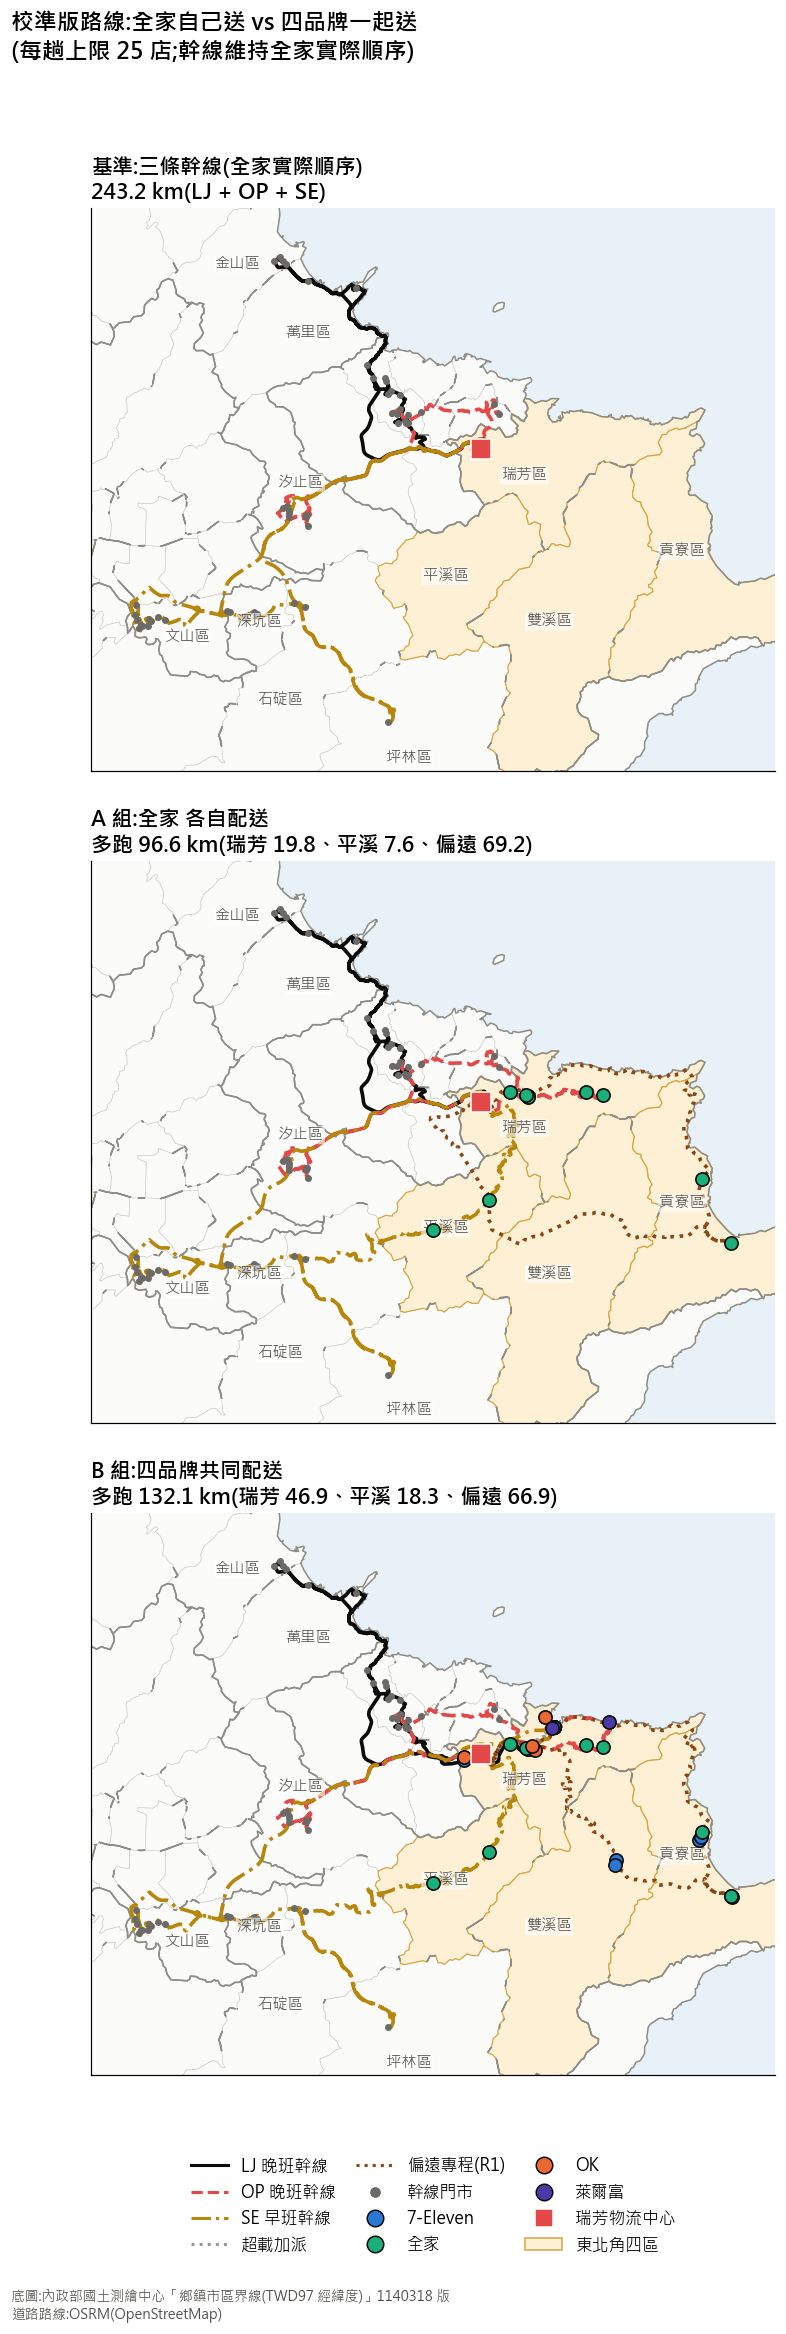

In [20]:
# 投影片用:只留「基準」「A 組:全家」「B 組」三格直排,字級放大,另存 PNG(poc/figures/)
sel = [0, 1 + BRANDS.index("全家"), len(cpanels) - 1]
fig, axes = plt.subplots(3, 1, figsize=(8, 21.5))
for ax, j in zip(axes, sel):
    draw_panel(ax, *cpanels[j], clines[j], big=True)
fig.legend(handles=cal_legend(big=True), loc="lower center", ncols=3, fontsize=11, frameon=False,
           bbox_to_anchor=(0.5, 0.025), columnspacing=1.2, handlelength=2.2)
fig.suptitle("校準版路線:全家自己送 vs 四品牌一起送\n(每趟上限 25 店;幹線維持全家實際順序)",
             x=0.02, ha="left", fontweight="bold", fontsize=15)
fig.text(0.02, 0.004, "底圖:內政部國土測繪中心「鄉鎮市區界線(TWD97 經緯度)」1140318 版\n道路路線:OSRM(OpenStreetMap)",
         fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0.1, 1, 0.955), h_pad=2.5)
os.makedirs(P("poc", "figures"), exist_ok=True)
fig.savefig(P("poc", "figures", "calibrated_routes_3panel.png"), dpi=200, bbox_inches="tight", facecolor="white")
plt.show()


## 8. 解讀與對提案的影響

In [21]:
# 三個版本並列
r1, r2 = CR[CR["情境"].str.startswith("R1")], CR[CR["情境"].str.startswith("R2")]
cmp_ = pd.DataFrame([
    {"版本": "PoC:專程配送", "假設": "每個品牌專程繞東北角一圈", "邊際里程減幅": "51%", "路網總里程減幅": "未計算"},
    {"版本": "版本一:重新最佳化(上限)", "假設": "10 店同一班次送完,可重排幹線",
     "邊際里程減幅": f"{R['邊際里程減幅'].min():.0%} ~ {R['邊際里程減幅'].max():.0%}",
     "路網總里程減幅": f"{R['路網總里程減幅'].min():.0%} ~ {R['路網總里程減幅'].max():.0%}"},
    {"版本": "校準版 R1:偏遠由瑞芳專程", "假設": "實際班次、幹線順序固定;貢寮雙溪專程",
     "邊際里程減幅": f"{r1['邊際里程減幅'].min():.0%} ~ {r1['邊際里程減幅'].max():.0%}",
     "路網總里程減幅": f"{r1['路網總里程減幅'].min():.0%} ~ {r1['路網總里程減幅'].max():.0%}"},
    {"版本": "校準版 R2:偏遠不納入", "假設": "實際班次、幹線順序固定;貢寮雙溪由他處配送",
     "邊際里程減幅": f"{r2['邊際里程減幅'].min():.0%} ~ {r2['邊際里程減幅'].max():.0%}",
     "路網總里程減幅": f"{r2['路網總里程減幅'].min():.0%} ~ {r2['路網總里程減幅'].max():.0%}"},
])
cmp_.style.hide(axis="index")

版本,假設,邊際里程減幅,路網總里程減幅
PoC:專程配送,每個品牌專程繞東北角一圈,51%,未計算
版本一:重新最佳化(上限),"10 店同一班次送完,可重排幹線",38% ~ 48%,6% ~ 16%
校準版 R1:偏遠由瑞芳專程,實際班次、幹線順序固定;貢寮雙溪專程,36% ~ 43%,6% ~ 8%
校準版 R2:偏遠不納入,實際班次、幹線順序固定;貢寮雙溪由他處配送,8% ~ 29%,1% ~ 2%


_(以下判讀依本次執行結果撰寫;若更動參數重跑,請一併檢查數字。)_

### 主要發現

1. **PoC 的「專程配送」假設不成立。** 全家的東北角門市全部是**順路**配送:瑞芳、九份、金瓜石的門市放在晚班 LJ、OP 的前段,平溪放在早班 SE 的回程,貢寮不由瑞芳物流中心配送。實際每停靠一家東北角門市平均只多跑 **3.8 km**,PoC 專程假設的每店 8.8 km 約為實際的 2.3 倍。
2. **版本一(重新最佳化)只能當上限。** 它算出邊際里程減 38–48%,但路線圖顯示求解器又讓各品牌繞東北角一大圈,等於回到專程配送;模型中全家每店 6.6 km,也遠高於實際的 3.8 km。
3. **校準版能重現全家的實際里程。** 照實際班次分區、幹線順序固定後,全家 8 家門市的模型邊際里程為每店 **3.4 km**,與實際 3.8 km 相差約 1 成,方法可以拿來推論他牌。
4. **校準版的減幅明顯較小,而且取決於偏遠門市由誰配送:**
   - **R1(貢寮、雙溪由瑞芳專程):** 邊際里程減 **36–43%**,路網總里程減 **6–8%**。
   - **R2(貢寮、雙溪不納入):** 邊際里程減 **8–29%**,路網總里程減 **1–2%**。
5. **省下的里程主要來自偏遠門市。** 每趟上限 25 店時,貢寮、雙溪 8 店的專程里程由 A 組 136.1 km 降為 B 組 66.9 km(減 51%);瑞芳區 22 店本來就幾乎在幹線上(A 組合計 52.7 km,每店約 2.4 km),共配只能再省 6–21 km。換句話說:**門市已經順路時,共配的空間很小;沒有順路幹線的門市才是共配的主要效益來源。**
6. **容量是瑞芳區能否省下來的關鍵。** 共配把 22 家門市加進同一組幹線:每趟上限 30 店時都塞得下,瑞芳區省 20.5 km;上限 25 店時有 5 店要加派車,只省 5.8 km;上限 22 店時,平溪的 B 組(23.5 km)甚至比 A 組(18.3 km)還多。目前容量以「店數」代替貨量,取得箱數或材積後才能確定。

### 對提案的影響

- 試作的「−51%」應改為**分層呈現**:專程假設 51% → 版本一上限 38–48% → 校準版 8–43%(依偏遠門市是否由瑞芳配送),路網總里程減 1–8%。
- 研究結論的重點應從「共配可大幅減碳」調整為**「共配效益集中在沒有順路幹線的偏遠門市」**,這也與函館實證的情境(地方、門市分散的區域)相符。
- 下一步最需要釐清的是**貢寮、雙溪門市實際由哪個物流中心配送**,因為 R1、R2 的差距(36–43% vs 8–29%)就來自這一點。

### 限制

1. **他牌的幹線與分區是假設的:** 他牌實際路線無法取得,假設其門市照同樣的分區插入全家的幹線。
2. **容量以店數代替貨量:** 沒有箱數或材積資料,每趟上限 22/25/30 店是情境假設。
3. **插入法是啟發式:** regret 插入不保證最佳解,但與實際量測邊際里程的口徑一致(幹線順序不動)。
4. **幹線以單一典型趟次代表:** 每條路線取一趟中位數趟次,未涵蓋各日變化;配送計畫在 456 天中只有約 350 天出現東北角門市。
5. **仍未納入時間窗、溫層相容與停靠怠速;** 只計行駛里程。

### 下一步(對應 11/3 初步結果)

1. **查證偏遠門市的配送來源:** 確認 7-Eleven 等他牌的貢寮、雙溪門市由哪個物流中心配送,決定採 R1 或 R2。
2. **配送頻次與年化:** 依各店每日實際被送幾次,推算全年減碳量。
3. **多日幹線:** 以多個實際日期的幹線重算校準版,得到減幅的分布。
4. **時間窗:** 以 TMS 表訂到店時間檢查共配插入後是否造成延誤。
5. **油耗模型:** 以 7 輛車的車日資料建立「里程 + 停靠 + 怠速」油耗模型,把減碳比例改以總油耗計算。

### 參考文獻

- Ballot, E., & Fontane, F. (2010). Reducing transportation CO₂ emissions through pooling of supply networks: Perspectives from a case study in French retail chains. *Production Planning & Control, 21*(6), 640–650. https://doi.org/10.1080/09537287.2010.489276
- Cruijssen, F., Bräysy, O., Dullaert, W., Fleuren, H., & Salomon, M. (2007). Joint route planning under varying market conditions. *International Journal of Physical Distribution & Logistics Management, 37*(4), 287–304. https://doi.org/10.1108/09600030710752514
- Gansterer, M., & Hartl, R. F. (2018). Collaborative vehicle routing: A survey. *European Journal of Operational Research, 268*(1), 1–12. https://doi.org/10.1016/j.ejor.2017.10.023
- Guajardo, M., & Rönnqvist, M. (2016). A review on cost allocation methods in collaborative transportation. *International Transactions in Operational Research, 23*(3), 371–392. https://doi.org/10.1111/itor.12205
- Krajewska, M. A., Kopfer, H., Laporte, G., Ropke, S., & Zaccour, G. (2008). Horizontal cooperation among freight carriers: Request allocation and profit sharing. *Journal of the Operational Research Society, 59*(11), 1483–1491. https://doi.org/10.1057/palgrave.jors.2602489
- Wouda, N. A., Lan, L., & Kool, W. (2024). PyVRP: A high-performance VRP solver package. *INFORMS Journal on Computing, 36*(4), 943–955. https://doi.org/10.1287/ijoc.2023.0055
- 日本全家等(2022 年 10 月 17 日)。大手コンビニ 3 社の地方(北海道)における共同配送の実証実験結果について〔新聞稿〕。https://www.family.co.jp/content/dam/family/company/news_releases/2022/20221017_newsrelease_03.pdf
- 經濟部統計處(2025 年 10 月 16 日)。我國便利商店營業額穩定成長,2025 年可望續創新高〔新聞稿〕。https://www.moea.gov.tw/MNS/populace/news/News.aspx?kind=1&menu_id=40&news_id=120778
- 環境部氣候變遷署(2026)。運輸部門:各部門排放及減量情形(引用國家溫室氣體排放清冊報告 2026 年版)。https://www.cca.gov.tw/climatetalks/emission-and-reduction/sectoral/transportation/1877.html